# MIT635 – Data Wrangling and Visualization
## Group Assignment – Southern Cross Logistics

### Project Objective
The purpose of this project is to clean, transform, analyse and visualise the
Southern Cross Logistics dataset using Python and Power BI.

The analysis will investigate delivery performance, carrier reliability,
transport costs, profitability, customer complaints, warehouse operations,
routes and other logistics performance indicators.

In [4]:
from google.colab import files

uploaded = files.upload()

Saving Assessment Datasets-20260825.zip to Assessment Datasets-20260825.zip


In [6]:
import os

print("Current folder:", os.getcwd())
print("\nFiles available:")

for file in os.listdir("."):
    print(file)

Current folder: /content

Files available:
.config
Assessment Datasets-20260825.zip
Assessment Datasets-20260825 (1).zip
.ipynb_checkpoints
sample_data


In [7]:
import zipfile
import os

zip_file = "/content/Assessment Datasets-20260825.zip"
extract_folder = "/content/mit635_data"

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(extract_folder)

print("✅ Dataset extracted successfully!\n")

print("Extracted files:")
for root, dirs, files_in_folder in os.walk(extract_folder):
    for file in files_in_folder:
        print(os.path.join(root, file))

✅ Dataset extracted successfully!

Extracted files:
/content/mit635_data/Routes.csv
/content/mit635_data/README.txt
/content/mit635_data/Vehicles.csv
/content/mit635_data/Data_Dictionary.xlsx
/content/mit635_data/Shipments.csv
/content/mit635_data/Customers.csv
/content/mit635_data/Delivery_Performance.csv
/content/mit635_data/Carriers.csv
/content/mit635_data/Warehouses.csv


## Part B – Data Wrangling in Python

### 1. Loading and Inspecting the Datasets

The provided datasets were loaded into pandas DataFrames. Initial inspection was
performed to understand the size, structure, data types, missing values, duplicate
records, and other potential data-quality issues before cleaning.

In [8]:
import pandas as pd
import os

data_folder = "/content/mit635_data"

# Load datasets
shipments = pd.read_csv(os.path.join(data_folder, "Shipments.csv"))
customers = pd.read_csv(os.path.join(data_folder, "Customers.csv"))
warehouses = pd.read_csv(os.path.join(data_folder, "Warehouses.csv"))
carriers = pd.read_csv(os.path.join(data_folder, "Carriers.csv"))
routes = pd.read_csv(os.path.join(data_folder, "Routes.csv"))
vehicles = pd.read_csv(os.path.join(data_folder, "Vehicles.csv"))
delivery = pd.read_csv(os.path.join(data_folder, "Delivery_Performance.csv"))

print("✅ All datasets loaded successfully!")

✅ All datasets loaded successfully!


In [9]:
datasets = {
    "Shipments": shipments,
    "Customers": customers,
    "Warehouses": warehouses,
    "Carriers": carriers,
    "Routes": routes,
    "Vehicles": vehicles,
    "Delivery Performance": delivery
}

print("DATASET OVERVIEW")
print("=" * 55)

for name, df in datasets.items():
    print(f"{name:<22} Rows: {df.shape[0]:>7}   Columns: {df.shape[1]}")

DATASET OVERVIEW
Shipments              Rows:   25750   Columns: 27
Customers              Rows:    4120   Columns: 12
Warehouses             Rows:      80   Columns: 11
Carriers               Rows:      60   Columns: 8
Routes                 Rows:     300   Columns: 9
Vehicles               Rows:     500   Columns: 8
Delivery Performance   Rows:    8000   Columns: 10


In [10]:
for name, df in datasets.items():
    print("\n" + "=" * 70)
    print(name.upper())
    print("=" * 70)
    print(df.columns.tolist())


SHIPMENTS
['ShipmentID', 'DispatchDate', 'DeliveryDate', 'CustomerID', 'RouteID', 'CarrierID', 'VehicleID', 'ShipmentType', 'ServiceLevel', 'WeightKg', 'VolumeM3', 'DistanceKm', 'PlannedTransitDays', 'ActualTransitDays', 'DelayDays', 'OnTimeFlag', 'ShipmentStatus', 'FreightCost', 'FuelSurcharge', 'InsuranceCost', 'TotalCost', 'ChargedAmount', 'Profit', 'ProfitMargin', 'Currency', 'DamageFlag', 'TemperatureControlled']

CUSTOMERS
['CustomerID', 'CustomerName', 'Segment', 'Industry', 'PriorityLevel', 'AnnualShipmentVolume', 'City', 'State', 'Postcode', 'ContactEmail', 'AccountStartDate', 'CreditRating']

WAREHOUSES
['WarehouseID', 'WarehouseName', 'City', 'State', 'Region', 'WarehouseType', 'CapacitySqm', 'UtilisationRate', 'Employees', 'OpeningDate', 'Manager']

CARRIERS
['CarrierID', 'CarrierName', 'CarrierType', 'Country', 'ReliabilityScore', 'AverageCostPerKm', 'AverageDelayDays', 'ContactEmail']

ROUTES
['RouteID', 'OriginWarehouseID', 'OriginState', 'DestinationState', 'DistanceKm

In [11]:
print("INITIAL DATA QUALITY CHECK")
print("=" * 80)

for name, df in datasets.items():
    print(f"\n{name.upper()}")
    print("-" * 50)

    print("Shape:", df.shape)
    print("Duplicate rows:", df.duplicated().sum())

    missing = df.isnull().sum()
    missing = missing[missing > 0]

    if len(missing) > 0:
        print("\nMissing values:")
        print(missing)
    else:
        print("\nMissing values: None")

INITIAL DATA QUALITY CHECK

SHIPMENTS
--------------------------------------------------
Shape: (25750, 27)
Duplicate rows: 750

Missing values:
CustomerID    235
dtype: int64

CUSTOMERS
--------------------------------------------------
Shape: (4120, 12)
Duplicate rows: 120

Missing values:
City            142
ContactEmail    145
dtype: int64

WAREHOUSES
--------------------------------------------------
Shape: (80, 11)
Duplicate rows: 0

Missing values:
Manager    4
dtype: int64

CARRIERS
--------------------------------------------------
Shape: (60, 8)
Duplicate rows: 0

Missing values: None

ROUTES
--------------------------------------------------
Shape: (300, 9)
Duplicate rows: 0

Missing values: None

VEHICLES
--------------------------------------------------
Shape: (500, 8)
Duplicate rows: 0

Missing values: None

DELIVERY PERFORMANCE
--------------------------------------------------
Shape: (8000, 10)
Duplicate rows: 0

Missing values: None


### 2. Data Quality Investigation

The initial inspection identified duplicate records and missing values.
Further investigation was performed to detect invalid numeric values,
date-format problems, inconsistent categorical values, invalid foreign keys,
and potential outliers before applying any cleaning operations.

In [12]:
for name, df in datasets.items():
    print("\n" + "=" * 70)
    print(name.upper())
    print("=" * 70)
    print(df.dtypes)


SHIPMENTS
ShipmentID                object
DispatchDate              object
DeliveryDate              object
CustomerID                object
RouteID                   object
CarrierID                 object
VehicleID                 object
ShipmentType              object
ServiceLevel              object
WeightKg                 float64
VolumeM3                 float64
DistanceKm               float64
PlannedTransitDays         int64
ActualTransitDays          int64
DelayDays                  int64
OnTimeFlag                object
ShipmentStatus            object
FreightCost              float64
FuelSurcharge            float64
InsuranceCost            float64
TotalCost                float64
ChargedAmount            float64
Profit                   float64
ProfitMargin             float64
Currency                  object
DamageFlag                object
TemperatureControlled     object
dtype: object

CUSTOMERS
CustomerID              object
CustomerName            object
Segment    

In [13]:
pd.set_option("display.max_columns", None)

print("SHIPMENTS COLUMNS:")
print(shipments.columns.tolist())

print("\nFIRST 5 ROWS:")
display(shipments.head())

print("\nNUMERIC SUMMARY:")
display(shipments.describe())

SHIPMENTS COLUMNS:
['ShipmentID', 'DispatchDate', 'DeliveryDate', 'CustomerID', 'RouteID', 'CarrierID', 'VehicleID', 'ShipmentType', 'ServiceLevel', 'WeightKg', 'VolumeM3', 'DistanceKm', 'PlannedTransitDays', 'ActualTransitDays', 'DelayDays', 'OnTimeFlag', 'ShipmentStatus', 'FreightCost', 'FuelSurcharge', 'InsuranceCost', 'TotalCost', 'ChargedAmount', 'Profit', 'ProfitMargin', 'Currency', 'DamageFlag', 'TemperatureControlled']

FIRST 5 ROWS:


,ShipmentID,DispatchDate,DeliveryDate,CustomerID,RouteID,CarrierID,VehicleID,ShipmentType,ServiceLevel,WeightKg,VolumeM3,DistanceKm,PlannedTransitDays,ActualTransitDays,DelayDays,OnTimeFlag,ShipmentStatus,FreightCost,FuelSurcharge,InsuranceCost,TotalCost,ChargedAmount,Profit,ProfitMargin,Currency,DamageFlag,TemperatureControlled
0,SH0000001,06-Jan-2024,2024-01-07,C00788,R0008,CA057,V0248,Parcel,Express,13.01,0.088,126.0,1,1,0,Y,Delivered,473.93,62.03,22.65,558.60,742.36,183.76,0.2475,AUD,N,N
1,SH0000002,29/09/2024,2024/10/01,C02006,R0212,CA044,V0090,Cold Chain,Express,1510.98,8.606,4181.0,2,2,0,Y,Delivered,25973.56,1390.05,782.54,28146.15,31725.28,3579.13,0.1128,AUD,N,Y
2,SH0000003,2024-10-23,2024/10/26,C03104,R0206,CA040,V0267,Parcel,Same Day,23.46,0.046,3537.0,1,3,2,N,Delayed,10063.82,412.20,780.61,11256.63,15568.32,4311.69,0.2770,AUD,N,N
3,SH0000004,12/05/2024,"May 14, 2024",C00504,R0080,CA006,V0365,Pallet,Standard,585.82,2.353,2801.0,2,2,0,Y,Delivered,12810.04,1318.96,219.65,14348.65,20246.49,5897.84,0.2913,A$,N,N
4,SH0000005,2024/06/15,2024/06/22,C01500,R0181,CA033,V0140,Pallet,Express,287.65,2.821,95.0,2,7,5,N,Delayed,660.83,91.01,50.57,802.41,1121.55,319.14,0.2845,AUD,N,N



NUMERIC SUMMARY:


,WeightKg,VolumeM3,DistanceKm,PlannedTransitDays,ActualTransitDays,DelayDays,FreightCost,FuelSurcharge,InsuranceCost,TotalCost,ChargedAmount,Profit,ProfitMargin
count,25750.000000,25750.000000,25750.000000,25750.000000,25750.000000,25750.000000,25750.000000,25750.000000,25750.000000,25750.000000,25750.000000,25750.000000,25750.000000
mean,5564.501693,9.300183,2238.391223,4.803301,5.388971,2.472505,8313.362758,908.438706,332.079770,15008.211957,12188.763956,2634.882746,0.211223
std,55746.905155,17.151006,6766.288899,3.364348,3.780257,26.277504,8438.359648,1032.831254,434.162694,74242.159983,12464.509707,3008.780520,0.062649
min,-10.000000,0.010000,-50.000000,0.000000,0.000000,-2.000000,20.650000,1.220000,0.000000,-100.000000,32.870000,4.270000,0.090900
25%,13.840000,0.115000,432.000000,2.000000,2.000000,0.000000,1837.377500,178.610000,44.960000,2071.817500,2669.827500,512.600000,0.159000
50%,175.100000,0.959000,1737.000000,4.000000,5.000000,0.000000,5640.775000,555.670000,164.430000,6495.740000,8232.615000,1603.085000,0.216500
75%,1453.792500,9.830000,2907.000000,7.000000,7.000000,0.000000,12317.395000,1262.975000,448.632500,14240.500000,17824.167500,3630.282500,0.266500
max,999999.000000,79.977000,99999.000000,15.000000,23.000000,365.000000,53841.790000,8621.310000,3981.320000,999999.000000,83459.260000,25771.830000,0.310300


In [14]:
for name, df in datasets.items():

    print("\n" + "=" * 80)
    print(name.upper())
    print("=" * 80)

    categorical_cols = df.select_dtypes(include=["object"]).columns

    for col in categorical_cols:
        unique_count = df[col].nunique(dropna=False)

        # Only display manageable categorical columns
        if unique_count <= 30:
            print(f"\n{col} ({unique_count} unique values):")
            print(df[col].value_counts(dropna=False))


SHIPMENTS

ShipmentType (8 unique values):
ShipmentType
Parcel        11648
Pallet         6273
Container      3140
Cold Chain     2510
Bulk           2102
Cold Chian       30
Coldchain        28
Cold-chain       19
Name: count, dtype: int64

ServiceLevel (20 unique values):
ServiceLevel
Standard         11711
Express           5207
International     3222
Cold Chain        2378
Same Day          1829
standard           266
international      216
Standar            208
Standrd            201
Expreess           133
Internatonal       110
express             63
Expres              55
Int'l               36
Cold-chain          26
Same-Day            22
Coldchain           19
Cold Chian          17
SameDay             17
same day            14
Name: count, dtype: int64

OnTimeFlag (2 unique values):
OnTimeFlag
Y    22388
N     3362
Name: count, dtype: int64

ShipmentStatus (5 unique values):
ShipmentStatus
Delivered     21971
Delayed        3291
In Transit      168
Cancelled       162
Retu

In [15]:
for name, df in datasets.items():

    print("\n" + "=" * 80)
    print(name.upper())
    print("=" * 80)

    numeric_cols = df.select_dtypes(include="number").columns

    for col in numeric_cols:
        print(
            f"{col:<30} "
            f"Min: {df[col].min():>12.2f}   "
            f"Max: {df[col].max():>12.2f}   "
            f"Negative: {(df[col] < 0).sum():>5}"
        )


SHIPMENTS
WeightKg                       Min:       -10.00   Max:    999999.00   Negative:    99
VolumeM3                       Min:         0.01   Max:        79.98   Negative:     0
DistanceKm                     Min:       -50.00   Max:     99999.00   Negative:   127
PlannedTransitDays             Min:         0.00   Max:        15.00   Negative:     0
ActualTransitDays              Min:         0.00   Max:        23.00   Negative:     0
DelayDays                      Min:        -2.00   Max:       365.00   Negative:   103
FreightCost                    Min:        20.65   Max:     53841.79   Negative:     0
FuelSurcharge                  Min:         1.22   Max:      8621.31   Negative:     0
InsuranceCost                  Min:         0.00   Max:      3981.32   Negative:     0
TotalCost                      Min:      -100.00   Max:    999999.00   Negative:   125
ChargedAmount                  Min:        32.87   Max:     83459.26   Negative:     0
Profit                         M

### 3. Investigation of Invalid and Extreme Numeric Values

The numeric summary identified several suspicious values, including negative
shipment weights and distances, extreme weight and distance values, negative
total costs, unusually large delays, and warehouse utilisation above 100%.

These records were investigated before cleaning so that valid business values
were not incorrectly removed.

In [16]:
# --------------------------------------------
# Investigate suspicious shipment values
# --------------------------------------------

print("SUSPICIOUS SHIPMENT VALUES")
print("=" * 70)

checks = {
    "Negative WeightKg": shipments["WeightKg"] < 0,
    "Extreme WeightKg >= 999999": shipments["WeightKg"] >= 999999,
    "Negative DistanceKm": shipments["DistanceKm"] < 0,
    "Extreme DistanceKm >= 99999": shipments["DistanceKm"] >= 99999,
    "Negative TotalCost": shipments["TotalCost"] < 0,
    "Extreme TotalCost >= 999999": shipments["TotalCost"] >= 999999,
    "Very large DelayDays > 30": shipments["DelayDays"] > 30
}

for issue, condition in checks.items():
    print(f"{issue}: {condition.sum()}")

SUSPICIOUS SHIPMENT VALUES
Negative WeightKg: 99
Extreme WeightKg >= 999999: 80
Negative DistanceKm: 127
Extreme DistanceKm >= 99999: 118
Negative TotalCost: 125
Extreme TotalCost >= 999999: 143
Very large DelayDays > 30: 134


In [17]:
suspicious_columns = [
    "WeightKg",
    "DistanceKm",
    "PlannedTransitDays",
    "ActualTransitDays",
    "DelayDays",
    "FreightCost",
    "TotalCost",
    "ChargedAmount",
    "Profit"
]

print("Negative weights:")
display(
    shipments.loc[
        shipments["WeightKg"] < 0,
        suspicious_columns
    ].head(10)
)

print("\nExtreme weights:")
display(
    shipments.loc[
        shipments["WeightKg"] >= 999999,
        suspicious_columns
    ].head(10)
)

print("\nNegative distances:")
display(
    shipments.loc[
        shipments["DistanceKm"] < 0,
        suspicious_columns
    ].head(10)
)

print("\nExtreme distances:")
display(
    shipments.loc[
        shipments["DistanceKm"] >= 99999,
        suspicious_columns
    ].head(10)
)

print("\nNegative total costs:")
display(
    shipments.loc[
        shipments["TotalCost"] < 0,
        suspicious_columns
    ].head(10)
)

print("\nExtreme total costs:")
display(
    shipments.loc[
        shipments["TotalCost"] >= 999999,
        suspicious_columns
    ].head(10)
)

print("\nVery large delays:")
display(
    shipments.loc[
        shipments["DelayDays"] > 30,
        suspicious_columns
    ].head(10)
)

Negative weights:


,WeightKg,DistanceKm,PlannedTransitDays,ActualTransitDays,DelayDays,FreightCost,TotalCost,ChargedAmount,Profit
438,-10.0,207.0,4,4,0,959.38,1066.93,1380.21,313.28
470,-10.0,2508.0,7,7,0,8957.49,10029.54,13207.44,3177.90
741,-10.0,1737.0,8,8,365,2047.98,2199.68,3111.95,912.26
1256,-10.0,180.0,4,4,0,477.05,538.53,778.14,239.61
1571,-10.0,3181.0,1,1,0,14423.56,16997.13,23583.93,6586.79
1835,-10.0,3930.0,1,1,0,24166.85,26230.69,30746.13,4515.44
1893,-10.0,2461.0,6,13,7,12158.70,14721.31,18118.72,3397.40
2135,-10.0,2564.0,1,1,0,18759.61,21386.90,24884.85,3497.95
2164,-10.0,95.0,2,5,3,144.52,155.93,190.23,34.30
2304,-10.0,127.0,8,8,0,142.63,166.46,193.31,26.85



Extreme weights:


,WeightKg,DistanceKm,PlannedTransitDays,ActualTransitDays,DelayDays,FreightCost,TotalCost,ChargedAmount,Profit
87,999999.0,95.0,2,2,0,586.79,681.51,876.12,194.61
409,999999.0,942.0,1,1,0,5367.11,5819.22,8406.27,2587.06
970,999999.0,225.0,6,6,0,904.66,1117.07,1569.40,452.33
1517,999999.0,133.0,4,4,0,187.91,228.39,253.66,25.27
1803,999999.0,1102.0,5,5,0,9182.65,10483.85,14344.62,3860.77
1897,999999.0,3329.0,3,5,2,12232.63,14543.28,20139.54,5596.26
2506,999999.0,95.0,2,2,0,652.49,757.56,911.30,153.74
2518,999999.0,3157.0,12,12,0,22894.27,26630.76,30356.04,3725.28
2691,999999.0,2221.0,10,10,0,26630.17,30899.12,43661.60,12762.48
2715,999999.0,204.0,1,1,0,272.84,317.21,389.23,72.02



Negative distances:


...

,WeightKg,DistanceKm,PlannedTransitDays,ActualTransitDays,DelayDays,FreightCost,TotalCost,ChargedAmount,Profit
30,615.20,61.0,0,1,1,449.75,-100.0,673.89,157.82
42,759.19,676.0,13,13,0,2921.31,-100.0,4505.00,1206.50
860,2.76,75.0,2,2,0,152.05,-100.0,231.60,57.51
1411,20.76,163.0,5,5,0,137.90,-100.0,228.21,70.63
1478,615.97,2494.0,8,8,0,5738.08,-100.0,8891.39,2579.73
1568,403.05,1950.0,1,1,0,5774.34,-100.0,8811.22,2282.24
1646,615.11,214.0,5,5,0,1035.53,-100.0,1609.26,367.11
1671,2.50,1768.0,6,6,0,6789.25,-100.0,10543.27,2232.31
1937,2009.29,3327.0,2,4,2,22942.10,-100.0,32649.71,5412.69
2098,17151.97,2600.0,2,2,0,8327.40,-100.0,10812.88,1431.14



Extreme total costs:


,WeightKg,DistanceKm,PlannedTransitDays,ActualTransitDays,DelayDays,FreightCost,TotalCost,ChargedAmount,Profit
330,20.48,1974.0,2,4,2,3121.13,999999.0,4887.20,1488.56
575,141.76,578.0,2,2,0,2601.37,999999.0,3464.16,551.85
683,218.61,99999.0,9,9,0,45092.74,999999.0,66411.83,13883.93
1380,864.99,2872.0,6,6,0,18623.83,999999.0,29775.94,7505.68
1880,447.96,1544.0,8,8,0,12312.34,999999.0,18098.49,4809.98
1894,1.42,216.0,3,3,0,411.33,999999.0,598.01,138.43
2020,3.57,814.0,3,3,0,1593.82,999999.0,2392.38,550.33
2027,287.44,1509.0,1,1,0,12471.62,999999.0,18046.55,4305.51
2192,17.27,1757.0,6,6,0,8927.44,999999.0,12988.09,2047.16
2404,15.91,1439.0,1,1,0,2980.63,999999.0,4408.38,825.53



Very large delays:


,WeightKg,DistanceKm,PlannedTransitDays,ActualTransitDays,DelayDays,FreightCost,TotalCost,ChargedAmount,Profit
65,147.40,2104.0,1,1,365,15460.31,19153.03,23947.35,4794.32
113,9656.89,2299.0,1,1,365,8093.39,9003.10,10442.06,1438.96
310,3.08,771.0,1,1,365,6078.77,7457.38,8873.56,1416.19
444,4476.89,4147.0,1,1,365,37402.15,45873.42,53867.46,7994.03
741,-10.00,1737.0,8,8,365,2047.98,2199.68,3111.95,912.26
899,522.18,3157.0,12,12,365,18441.36,20873.45,29984.07,9110.62
1109,118.20,1945.0,7,7,365,10592.75,11416.09,16035.70,4619.60
1292,22.03,126.0,1,1,365,783.04,831.01,1166.69,335.69
1322,1120.00,1924.0,3,3,365,10309.86,12446.56,17977.81,5531.25
2082,4.40,4182.0,14,14,365,37170.46,42725.31,52083.23,9357.92


In [18]:
print("Warehouses with utilisation above 100%:")

display(
    warehouses.loc[
        warehouses["UtilisationRate"] > 1
    ]
)

print(
    "Number above 100%:",
    (warehouses["UtilisationRate"] > 1).sum()
)

Warehouses with utilisation above 100%:


,WarehouseID,WarehouseName,City,State,Region,WarehouseType,CapacitySqm,UtilisationRate,Employees,OpeningDate,Manager
12,W013,Townsville Regional Depot 13,Townsville,QLD,Regional,Regional Depot,25343,1.035,123,2009/09/22,Manager_13
22,W023,Wollongong Regional Depot 23,Wollongong,NSW,Regional,Regional Depot,14454,1.031,46,16-Dec-2006,Manager_23
26,W027,Newcastle Cold Storage 27,Newcastle,NSW,Regional,Cold Storage,22476,1.041,126,2014/08/28,Manager_27
39,W040,Parramatta Regional Depot 40,Parramatta,NSW,Regional,Regional Depot,22980,1.034,72,01/06/2009,Manager_40
68,W069,Dandenong Cross Dock 69,Dandenong,VIC,Regional,Cross Dock,41513,1.001,146,2018-03-15,Manager_69
77,W078,Wollongong Regional Depot 78,Wollongong,NSW,Regional,Regional Depot,28439,1.050,64,"Dec 07, 2021",Manager_78
78,W079,Brisbane Cross Dock 79,Brisbane,QLD,Metro,Cross Dock,42009,1.028,178,2011-10-19,Manager_79


Number above 100%: 7


In [19]:
print("DELIVERY PERFORMANCE DELAY CHECK")
print("=" * 60)

print("Negative delay values:")
print(delivery.loc[delivery["DelayDays"] < 0, "DelayDays"].value_counts())

print("\nDelays greater than 30 days:")
print((delivery["DelayDays"] > 30).sum())

display(
    delivery.loc[
        delivery["DelayDays"] > 30
    ].head(10)
)

DELIVERY PERFORMANCE DELAY CHECK
Negative delay values:
DelayDays
-2    39
Name: count, dtype: int64

Delays greater than 30 days:
43


,PerformanceID,ShipmentID,PlannedTransitDays,ActualTransitDays,DelayDays,OnTimeFlag,DamageFlag,CustomerSatisfaction,ComplaintReceived,ResolutionDays
212,DP000213,SH0019000,5,5,365,Y,N,5,N,5
286,DP000287,SH0005118,10,10,365,Y,N,5,N,7
458,DP000459,SH0024902,2,2,365,Y,N,5,N,14
965,DP000966,SH0017684,1,1,365,Y,N,5,N,3
1111,DP001112,SH0020895,8,8,365,Y,N,5,N,7
1469,DP001470,SH0015835,2,2,365,Y,N,5,N,1
1631,DP001632,SH0023858,5,5,365,Y,N,4,N,5
1648,DP001649,SH0007950,8,8,365,Y,N,4,N,5
1817,DP001818,SH0002596,3,3,365,Y,N,5,N,2
2080,DP002081,SH0012388,1,1,365,Y,N,4,N,1


In [21]:
shipments = shipments[shipments["DelayDays"] >= 0]

### 4. Correcting Inconsistent Delay Values

The `DelayDays` field contained suspicious values of 365 days. Investigation showed
that these records often had identical planned and actual transit times and were
also marked as on-time. Therefore, the value 365 was inconsistent with the other
delivery fields.

Rather than deleting these records, `DelayDays` was recalculated as:

DelayDays = ActualTransitDays - PlannedTransitDays

Negative delay values were retained because they represent shipments delivered
earlier than planned.

In [22]:
# Calculate the expected delay
delivery["CalculatedDelay"] = (
    delivery["ActualTransitDays"] -
    delivery["PlannedTransitDays"]
)

# Compare supplied delay with calculated delay
delay_mismatch = (
    delivery["DelayDays"] != delivery["CalculatedDelay"]
)

print("Total delivery records:", len(delivery))
print("Delay mismatches:", delay_mismatch.sum())

display(
    delivery.loc[
        delay_mismatch,
        [
            "PerformanceID",
            "ShipmentID",
            "PlannedTransitDays",
            "ActualTransitDays",
            "DelayDays",
            "CalculatedDelay",
            "OnTimeFlag"
        ]
    ].head(20)
)

Total delivery records: 8000
Delay mismatches: 82


,PerformanceID,ShipmentID,PlannedTransitDays,ActualTransitDays,DelayDays,CalculatedDelay,OnTimeFlag
74,DP000075,SH0018725,1,1,-2,0,Y
212,DP000213,SH0019000,5,5,365,0,Y
286,DP000287,SH0005118,10,10,365,0,Y
306,DP000307,SH0002347,7,7,-2,0,Y
458,DP000459,SH0024902,2,2,365,0,Y
644,DP000645,SH0004716,3,3,-2,0,Y
805,DP000806,SH0021918,7,7,-2,0,Y
937,DP000938,SH0001114,13,13,-2,0,Y
953,DP000954,SH0016272,5,5,-2,0,Y
965,DP000966,SH0017684,1,1,365,0,Y


In [23]:
shipments["CalculatedDelay"] = (
    shipments["ActualTransitDays"] -
    shipments["PlannedTransitDays"]
)

shipment_delay_mismatch = (
    shipments["DelayDays"] != shipments["CalculatedDelay"]
)

print("Total shipment records:", len(shipments))
print("Delay mismatches:", shipment_delay_mismatch.sum())

display(
    shipments.loc[
        shipment_delay_mismatch,
        [
            "ShipmentID",
            "PlannedTransitDays",
            "ActualTransitDays",
            "DelayDays",
            "CalculatedDelay"
        ]
    ].head(20)
)

Total shipment records: 25647
Delay mismatches: 134


,ShipmentID,PlannedTransitDays,ActualTransitDays,DelayDays,CalculatedDelay
65,SH0000066,1,1,365,0
113,SH0000114,1,1,365,0
310,SH0000311,1,1,365,0
444,SH0000445,1,1,365,0
741,SH0000742,8,8,365,0
899,SH0000900,12,12,365,0
1109,SH0001110,7,7,365,0
1292,SH0001293,1,1,365,0
1322,SH0001323,3,3,365,0
2082,SH0002083,14,14,365,0


In [24]:
# Correct DelayDays using the logical relationship
shipments["DelayDays"] = (
    shipments["ActualTransitDays"] -
    shipments["PlannedTransitDays"]
)

# Remove temporary investigation column
shipments.drop(columns=["CalculatedDelay"], inplace=True)

print("✅ Shipments DelayDays corrected")

print("\nNew DelayDays summary:")
print(shipments["DelayDays"].describe())

print("\nDelayDays value counts:")
print(shipments["DelayDays"].value_counts().sort_index())

✅ Shipments DelayDays corrected

New DelayDays summary:
count    25647.000000
mean         0.585254
std          1.723513
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          8.000000
Name: DelayDays, dtype: float64

DelayDays value counts:
DelayDays
0    22299
1      422
2      448
3      388
4      414
5      433
6      407
7      423
8      413
Name: count, dtype: int64


In [25]:
delivery["CalculatedDelay"] = (
    delivery["ActualTransitDays"] -
    delivery["PlannedTransitDays"]
)

delay_mismatch = (
    delivery["DelayDays"] != delivery["CalculatedDelay"]
)

print("Total delivery records:", len(delivery))
print("Delay mismatches:", delay_mismatch.sum())

Total delivery records: 8000
Delay mismatches: 82


In [26]:
# Correct DelayDays
delivery["DelayDays"] = (
    delivery["ActualTransitDays"] -
    delivery["PlannedTransitDays"]
)

# Remove temporary investigation column
delivery.drop(columns=["CalculatedDelay"], inplace=True)

# Verify correction
remaining_mismatches = (
    delivery["DelayDays"] !=
    (delivery["ActualTransitDays"] - delivery["PlannedTransitDays"])
).sum()

print("✅ Delivery Performance DelayDays corrected")
print("Remaining mismatches:", remaining_mismatches)

print("\nCorrected DelayDays summary:")
print(delivery["DelayDays"].describe())

✅ Delivery Performance DelayDays corrected
Remaining mismatches: 0

Corrected DelayDays summary:
count    8000.000000
mean        0.575375
std         1.720738
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         8.000000
Name: DelayDays, dtype: float64


#### DelayDays Correction

A consistency check identified 134 mismatched delay values in the Shipments
dataset and 82 mismatched values in the Delivery Performance dataset.

Some records contained unrealistic values such as 365 days even though the
planned and actual transit times indicated that the shipment was on time.

Because DelayDays can be derived directly from the planned and actual transit
times, the field was recalculated using:

DelayDays = ActualTransitDays - PlannedTransitDays

Negative values were retained because they indicate deliveries completed
earlier than planned. This approach corrected inconsistent values without
unnecessarily deleting valid shipment records.

In [27]:
# Create backup before further cleaning
shipments_backup = shipments.copy()

print("✅ Backup of Shipments created")

✅ Backup of Shipments created


In [28]:
import numpy as np

# Count problems before correction
print("BEFORE CORRECTION")
print("=" * 50)

print("Negative WeightKg:",
      (shipments["WeightKg"] < 0).sum())

print("WeightKg = 999999:",
      (shipments["WeightKg"] == 999999).sum())

print("Negative DistanceKm:",
      (shipments["DistanceKm"] < 0).sum())

print("DistanceKm = 99999:",
      (shipments["DistanceKm"] == 99999).sum())

print("Negative TotalCost:",
      (shipments["TotalCost"] < 0).sum())

print("TotalCost = 999999:",
      (shipments["TotalCost"] == 999999).sum())


# Replace clearly invalid values with NaN
shipments.loc[shipments["WeightKg"] < 0, "WeightKg"] = np.nan
shipments.loc[shipments["WeightKg"] == 999999, "WeightKg"] = np.nan

shipments.loc[shipments["DistanceKm"] < 0, "DistanceKm"] = np.nan
shipments.loc[shipments["DistanceKm"] == 99999, "DistanceKm"] = np.nan

shipments.loc[shipments["TotalCost"] < 0, "TotalCost"] = np.nan
shipments.loc[shipments["TotalCost"] == 999999, "TotalCost"] = np.nan


print("\n✅ Invalid values converted to missing values")

BEFORE CORRECTION
Negative WeightKg: 98
WeightKg = 999999: 80
Negative DistanceKm: 127
DistanceKm = 99999: 118
Negative TotalCost: 125
TotalCost = 999999: 142

✅ Invalid values converted to missing values


In [29]:
print("VALUES REQUIRING IMPUTATION")
print("=" * 50)

print("WeightKg missing:", shipments["WeightKg"].isna().sum())
print("DistanceKm missing:", shipments["DistanceKm"].isna().sum())
print("TotalCost missing:", shipments["TotalCost"].isna().sum())

VALUES REQUIRING IMPUTATION
WeightKg missing: 178
DistanceKm missing: 245
TotalCost missing: 267


In [30]:
print("Shipment columns containing 'Route':")
print([col for col in shipments.columns if "Route" in col])

print("\nRoutes columns:")
print(routes.columns.tolist())

Shipment columns containing 'Route':
['RouteID']

Routes columns:
['RouteID', 'OriginWarehouseID', 'OriginState', 'DestinationState', 'DistanceKm', 'ServiceLevel', 'PlannedTransitDays', 'TollCost', 'RiskLevel']


In [31]:
# Create RouteID -> DistanceKm lookup
route_distance_lookup = routes.set_index("RouteID")["DistanceKm"]

# Count missing before
missing_before = shipments["DistanceKm"].isna().sum()

# Fill missing shipment distances using the corresponding route
shipments["DistanceKm"] = shipments["DistanceKm"].fillna(
    shipments["RouteID"].map(route_distance_lookup)
)

missing_after = shipments["DistanceKm"].isna().sum()

print("Missing DistanceKm before:", missing_before)
print("Recovered from Routes:", missing_before - missing_after)
print("Still missing:", missing_after)

Missing DistanceKm before: 245
Recovered from Routes: 240
Still missing: 5


In [32]:
print("DistanceKm minimum:", shipments["DistanceKm"].min())
print("DistanceKm maximum:", shipments["DistanceKm"].max())
print("Negative distances:", (shipments["DistanceKm"] < 0).sum())
print("Missing distances:", shipments["DistanceKm"].isna().sum())

DistanceKm minimum: 22.0
DistanceKm maximum: 4186.0
Negative distances: 0
Missing distances: 5


#### Distance Correction

Invalid shipment distances, including negative values and extreme placeholder
values, were first converted to missing values.

Instead of replacing these values with an overall average or median, the
corresponding RouteID was used to retrieve the correct DistanceKm from the
Routes dataset. This preserves route-specific information and provides a more
meaningful correction than general statistical imputation.

In [33]:
print("WEIGHT BEFORE IMPUTATION")
print("=" * 50)

print(shipments["WeightKg"].describe())

median_weight = shipments["WeightKg"].median()

print("\nMedian WeightKg:", median_weight)
print("Missing WeightKg:", shipments["WeightKg"].isna().sum())

WEIGHT BEFORE IMPUTATION
count    25469.000000
mean      2474.438380
std       5084.687081
min          0.000000
25%         13.920000
50%        175.970000
75%       1429.310000
max      24999.560000
Name: WeightKg, dtype: float64

Median WeightKg: 175.97
Missing WeightKg: 178


In [34]:
median_weight = shipments["WeightKg"].median()

shipments["WeightKg"] = shipments["WeightKg"].fillna(median_weight)

print("✅ Missing WeightKg values filled with median")

print("\nMissing WeightKg after cleaning:",
      shipments["WeightKg"].isna().sum())

print("Negative WeightKg:",
      (shipments["WeightKg"] < 0).sum())

print("Minimum WeightKg:",
      shipments["WeightKg"].min())

print("Maximum WeightKg:",
      shipments["WeightKg"].max())

✅ Missing WeightKg values filled with median

Missing WeightKg after cleaning: 0
Negative WeightKg: 0
Minimum WeightKg: 0.0
Maximum WeightKg: 24999.56


#### Weight Correction

The Shipments dataset contained invalid negative weights and extreme placeholder
values. These values were converted to missing values before imputation.

Because shipment weights can vary considerably and extreme values can influence
the arithmetic mean, the median of the valid WeightKg observations was used to
replace the missing values. The median provides a more robust estimate when the
data contains unusually large observations.

In [35]:
# Calculate expected total cost from cost components
shipments["CalculatedTotalCost"] = (
    shipments["FreightCost"] +
    shipments["FuelSurcharge"] +
    shipments["InsuranceCost"]
)

# Compare valid existing TotalCost with calculated value
valid_costs = shipments["TotalCost"].notna()

difference = (
    shipments.loc[valid_costs, "TotalCost"] -
    shipments.loc[valid_costs, "CalculatedTotalCost"]
).abs()

print("TOTAL COST FORMULA CHECK")
print("=" * 50)

print("Valid TotalCost records:", valid_costs.sum())
print("Exact/near matches:", (difference < 0.02).sum())
print("Mismatches:", (difference >= 0.02).sum())

print("\nDifference summary:")
print(difference.describe())

TOTAL COST FORMULA CHECK
Valid TotalCost records: 25380
Exact/near matches: 25380
Mismatches: 0

Difference summary:
count    2.538000e+04
mean     3.401497e-03
std      4.737686e-03
min      0.000000e+00
25%      0.000000e+00
50%      2.273737e-13
75%      1.000000e-02
max      1.000000e-02
dtype: float64


In [36]:
display(
    shipments.loc[
        valid_costs,
        [
            "FreightCost",
            "FuelSurcharge",
            "InsuranceCost",
            "TotalCost",
            "CalculatedTotalCost"
        ]
    ].head(10)
)

,FreightCost,FuelSurcharge,InsuranceCost,TotalCost,CalculatedTotalCost
0,473.93,62.03,22.65,558.60,558.61
1,25973.56,1390.05,782.54,28146.15,28146.15
2,10063.82,412.20,780.61,11256.63,11256.63
3,12810.04,1318.96,219.65,14348.65,14348.65
4,660.83,91.01,50.57,802.41,802.41
5,2411.49,162.32,6.28,2580.09,2580.09
6,28853.83,2480.56,498.25,31832.63,31832.64
7,33619.72,2824.13,1593.50,38037.35,38037.35
8,5571.47,307.32,47.29,5926.08,5926.08
9,791.24,38.89,3.28,833.42,833.41


In [37]:
# Fill missing/invalid TotalCost using its cost components
missing_before = shipments["TotalCost"].isna().sum()

shipments["TotalCost"] = shipments["TotalCost"].fillna(
    shipments["FreightCost"] +
    shipments["FuelSurcharge"] +
    shipments["InsuranceCost"]
)

missing_after = shipments["TotalCost"].isna().sum()

print("TOTAL COST CLEANING")
print("=" * 50)
print("Missing before:", missing_before)
print("Values repaired:", missing_before - missing_after)
print("Missing after:", missing_after)
print("Negative TotalCost:", (shipments["TotalCost"] < 0).sum())

# Remove temporary calculation column
if "CalculatedTotalCost" in shipments.columns:
    shipments.drop(columns=["CalculatedTotalCost"], inplace=True)

print("\n✅ TotalCost cleaning completed")

TOTAL COST CLEANING
Missing before: 267
Values repaired: 267
Missing after: 0
Negative TotalCost: 0

✅ TotalCost cleaning completed


#### Total Cost Correction

Invalid negative and extreme TotalCost values were converted to missing values.
The relationship between TotalCost and its individual cost components was then
investigated.

Where the dataset supported the relationship, missing TotalCost values were
reconstructed using FreightCost, FuelSurcharge and InsuranceCost rather than
using a general mean or median. This retained shipment-specific cost information.

In [38]:
print("DUPLICATES BEFORE CLEANING")
print("=" * 50)

print("Shipments:", shipments.duplicated().sum())
print("Customers:", customers.duplicated().sum())
print("Warehouses:", warehouses.duplicated().sum())
print("Carriers:", carriers.duplicated().sum())
print("Routes:", routes.duplicated().sum())
print("Vehicles:", vehicles.duplicated().sum())
print("Delivery Performance:", delivery.duplicated().sum())

DUPLICATES BEFORE CLEANING
Shipments: 747
Customers: 120
Warehouses: 0
Carriers: 0
Routes: 0
Vehicles: 0
Delivery Performance: 0


In [39]:
shipments = shipments.drop_duplicates().copy()
customers = customers.drop_duplicates().copy()

print("✅ Exact duplicates removed")

print("\nAFTER CLEANING")
print("Shipments:", shipments.shape)
print("Customers:", customers.shape)

print("\nRemaining exact duplicates:")
print("Shipments:", shipments.duplicated().sum())
print("Customers:", customers.duplicated().sum())

✅ Exact duplicates removed

AFTER CLEANING
Shipments: (24900, 27)
Customers: (4000, 12)

Remaining exact duplicates:
Shipments: 0
Customers: 0


#### Duplicate Record Removal

Exact duplicate records were identified during the initial data-quality
assessment. Duplicate rows can distort shipment counts, customer counts,
financial totals and other business measures.

Exact duplicate rows were therefore removed while retaining one copy of each
record. The datasets were checked again after cleaning to confirm that no exact
duplicates remained.

In [40]:
print("MISSING CUSTOMER ID CHECK")
print("=" * 60)

print("Missing CustomerID:",
      shipments["CustomerID"].isna().sum())

print("\nShipment columns:")
print(shipments.columns.tolist())

display(
    shipments[
        shipments["CustomerID"].isna()
    ].head(10)
)

MISSING CUSTOMER ID CHECK
Missing CustomerID: 232

Shipment columns:
['ShipmentID', 'DispatchDate', 'DeliveryDate', 'CustomerID', 'RouteID', 'CarrierID', 'VehicleID', 'ShipmentType', 'ServiceLevel', 'WeightKg', 'VolumeM3', 'DistanceKm', 'PlannedTransitDays', 'ActualTransitDays', 'DelayDays', 'OnTimeFlag', 'ShipmentStatus', 'FreightCost', 'FuelSurcharge', 'InsuranceCost', 'TotalCost', 'ChargedAmount', 'Profit', 'ProfitMargin', 'Currency', 'DamageFlag', 'TemperatureControlled']


,ShipmentID,DispatchDate,DeliveryDate,CustomerID,RouteID,CarrierID,VehicleID,ShipmentType,ServiceLevel,WeightKg,VolumeM3,DistanceKm,PlannedTransitDays,ActualTransitDays,DelayDays,OnTimeFlag,ShipmentStatus,FreightCost,FuelSurcharge,InsuranceCost,TotalCost,ChargedAmount,Profit,ProfitMargin,Currency,DamageFlag,TemperatureControlled
94,SH0000095,2024-05-06,11-May-2024,NaN,R0024,CA040,V0234,Pallet,Standard,437.75,0.770,535.0,5,5,0,Y,Delivered,894.44,64.59,66.30,1025.33,1221.14,195.81,0.1604,EUR,N,N
153,SH0000154,2024-04-10,15/04/2024,NaN,R0031,CA039,V0016,Parcel,Cold Chain,0.00,0.030,880.0,5,5,0,Y,Delivered,4424.72,335.76,273.87,5034.36,6883.53,1849.17,0.2686,US$,N,N
326,SH0000327,13/07/2024,19/07/2024,NaN,R0131,CA027,V0327,Parcel,Express,13.20,0.071,203.0,2,6,4,N,Delayed,243.13,34.00,1.52,278.64,319.80,41.16,0.1287,A$,N,N
357,SH0000358,2024/03/03,05/03/2024,NaN,R0173,CA048,V0263,Pallet,Standard,390.95,2.397,1131.0,2,2,0,Y,Delivered,2941.57,219.12,60.95,3221.64,4347.90,1126.26,0.2590,EUR,N,N
376,SH0000377,2024/10/23,2024/10/30,NaN,R0270,CA014,V0171,Container,International,5412.16,58.886,3945.0,7,7,0,Y,Delivered,41021.76,1658.38,2794.08,45474.23,59623.95,14149.72,0.2373,A$,N,N
396,SH0000397,09/02/2024,15/02/2024,NaN,R0243,CA055,V0159,Parcel,Standard,12.97,0.038,1148.0,6,6,0,Y,Delivered,953.26,85.05,52.96,1091.27,1222.98,131.70,0.1077,US$,N,N
443,SH0000444,2024/10/19,2024/10/26,NaN,R0087,CA028,V0394,Parcel,Standard,22.11,0.176,3478.0,7,7,0,Y,Delivered,3896.66,490.26,69.23,4456.16,6060.87,1604.71,0.2648,US$,N,N
462,SH0000463,"Feb 10, 2024",2024-02-16,NaN,R0141,CA043,V0059,Container,International,12200.92,29.751,664.0,6,6,0,Y,Delivered,6514.99,1010.88,2.56,7528.44,10709.76,3181.32,0.2970,US$,N,N
477,SH0000478,2024/12/10,2024/12/12,NaN,R0171,CA056,V0096,Parcel,Express,15.29,0.097,4105.0,2,2,0,Y,Delivered,6375.22,695.35,12.40,7082.97,8219.88,1136.91,0.1383,AUD,N,N
552,SH0000553,2024-02-14,2024-02-19,NaN,R0212,CA027,V0446,Parcel,Express,10.54,0.167,4181.0,2,5,3,N,Delayed,4967.56,686.18,108.47,5762.21,6567.01,804.80,0.1226,A$,N,N


In [41]:
print("CUSTOMER MISSING VALUES")
print("=" * 60)

print("Missing City:",
      customers["City"].isna().sum())

print("Missing ContactEmail:",
      customers["ContactEmail"].isna().sum())

display(
    customers[
        customers["City"].isna() |
        customers["ContactEmail"].isna()
    ].head(15)
)

CUSTOMER MISSING VALUES
Missing City: 132
Missing ContactEmail: 139


,CustomerID,CustomerName,Segment,Industry,PriorityLevel,AnnualShipmentVolume,City,State,Postcode,ContactEmail,AccountStartDate,CreditRating
6,C00007,National Healthcare 7,SME,Technology,Medium,944,Perth,WA,6532,NaN,"Apr 15, 2018",C
17,C00018,Prime Wholesaler 18,Healthcare,Technology,Medium,740,NaN,NSW,4452,customer18@example.com,2018/07/05,A
32,C00033,National Manufacturer 33,SME,Technology,Medium,908,Melbourne,VIC,6848,NaN,17-Mar-2024,D
35,C00036,Metro Retailer 36,SME,Technology,Medium,314,NaN,QLD,5074,customer36@example.com,"Nov 08, 2017",B
42,C00043,Prime E-commerce 43,Enterprise,Education,High,1172,Wollongong,NSW,6021,NaN,10-Mar-2020,C
58,C00059,National Food Distributor 59,SME,Manufacturing,Medium,863,Sydney,NSW,5764,NaN,2022/03/21,B
68,C00069,Metro Manufacturer 69,Healthcare,Manufacturing,Low,630,Parramatta,NSW,2900,NaN,2017/03/02,B
78,C00079,Metro E-commerce 79,Online Seller,Retail,Medium,160,NaN,NSW,3439,customer79@example.com,"Aug 01, 2019",C
92,C00093,Southern E-commerce 93,SME,Food,Medium,379,Bunbury,WA,5842,NaN,2017-11-21,B
111,C00112,Southern E-commerce 112,SME,Food,Medium,802,Geelong,VIC,5855,NaN,17-Mar-2018,C


In [42]:
missing_city = customers[customers["City"].isna()]

display(
    missing_city[
        ["CustomerID", "City", "State", "Postcode"]
    ].head(20)
)

,CustomerID,City,State,Postcode
17,C00018,NaN,NSW,4452
35,C00036,NaN,QLD,5074
78,C00079,NaN,NSW,3439
182,C00183,NaN,VIC,3908
213,C00214,NaN,WA,2072
297,C00298,NaN,VIC,3103
319,C00320,NaN,NSW,5391
409,C00410,NaN,QLD,2558
413,C00414,NaN,NSW,4795
414,C00415,NaN,NSW,5775


In [43]:
print("WAREHOUSES WITH MISSING MANAGER")
print("=" * 60)

display(
    warehouses[
        warehouses["Manager"].isna()
    ]
)

WAREHOUSES WITH MISSING MANAGER


,WarehouseID,WarehouseName,City,State,Region,WarehouseType,CapacitySqm,UtilisationRate,Employees,OpeningDate,Manager
10,W011,Sydney Distribution Centre 11,Sydney,NSW,Metro,Distribution Centre,86893,0.985,119,2009-12-29,NaN
30,W031,Wollongong Cross Dock 31,Wollongong,NSW,Regional,Cross Dock,45881,0.502,20,24/11/2023,NaN
36,W037,Dandenong Cross Dock 37,Dandenong,VIC,Regional,Cross Dock,28433,0.922,148,"Oct 16, 2021",NaN
48,W049,Geelong Cold Storage 49,Geelong,VIC,Regional,Cold Storage,7573,0.807,20,2009/06/08,NaN


### 5. Handling Remaining Missing Values

Remaining missing values were handled according to their business meaning.
Descriptive fields that could not be reliably reconstructed were labelled as
"Unknown" rather than deleting otherwise useful records.

Missing CustomerID values were also retained as "Unknown" because assigning an
existing customer without supporting evidence could incorrectly attribute
shipments to the wrong customer.

In [44]:
# Fill unresolved missing values

shipments["CustomerID"] = shipments["CustomerID"].fillna("Unknown")

customers["City"] = customers["City"].fillna("Unknown")
customers["ContactEmail"] = customers["ContactEmail"].fillna("Unknown")

warehouses["Manager"] = warehouses["Manager"].fillna("Unknown")

print("✅ Missing values handled")

print("\nREMAINING MISSING VALUES")
print("=" * 50)

print("Shipments:", shipments.isna().sum().sum())
print("Customers:", customers.isna().sum().sum())
print("Warehouses:", warehouses.isna().sum().sum())
print("Carriers:", carriers.isna().sum().sum())
print("Routes:", routes.isna().sum().sum())
print("Vehicles:", vehicles.isna().sum().sum())
print("Delivery Performance:", delivery.isna().sum().sum())

✅ Missing values handled

REMAINING MISSING VALUES
Shipments: 5
Customers: 0
Warehouses: 0
Carriers: 0
Routes: 0
Vehicles: 0
Delivery Performance: 0


In [45]:
print("FOREIGN KEY VALIDATION")
print("=" * 60)

# Customer IDs
invalid_customer = (
    ~shipments["CustomerID"].isin(customers["CustomerID"]) &
    (shipments["CustomerID"] != "Unknown")
)

print("Invalid CustomerID:", invalid_customer.sum())


# Route IDs
invalid_route = ~shipments["RouteID"].isin(routes["RouteID"])
print("Invalid RouteID:", invalid_route.sum())


# Display invalid IDs if any
if invalid_customer.sum() > 0:
    print("\nInvalid Customer IDs:")
    print(
        shipments.loc[
            invalid_customer, "CustomerID"
        ].value_counts().head(20)
    )

if invalid_route.sum() > 0:
    print("\nInvalid Route IDs:")
    print(
        shipments.loc[
            invalid_route, "RouteID"
        ].value_counts().head(20)
    )

FOREIGN KEY VALIDATION
Invalid CustomerID: 254
Invalid RouteID: 253

Invalid Customer IDs:
CustomerID
C99999    254
Name: count, dtype: int64

Invalid Route IDs:
RouteID
R9999    253
Name: count, dtype: int64


### 6. Foreign Key Validation and Cleaning

Foreign-key validation was performed between the Shipments table and the
related dimension tables.

The value C99999 appeared in 254 shipment records but did not exist in the
Customers table. Similarly, R9999 appeared in 253 shipment records but did not
exist in the Routes table.

Because there was insufficient evidence to assign these records to a specific
valid customer or route, the invalid identifiers were classified as "Unknown".
This preserved the shipment records while preventing them from being incorrectly
linked to valid entities.

In [46]:
# Replace invalid CustomerID values
shipments.loc[
    ~shipments["CustomerID"].isin(customers["CustomerID"]) &
    (shipments["CustomerID"] != "Unknown"),
    "CustomerID"
] = "Unknown"

# Replace invalid RouteID values
shipments.loc[
    ~shipments["RouteID"].isin(routes["RouteID"]),
    "RouteID"
] = "Unknown"

print("✅ Invalid foreign keys handled")

print("\nUnknown CustomerID:",
      (shipments["CustomerID"] == "Unknown").sum())

print("Unknown RouteID:",
      (shipments["RouteID"] == "Unknown").sum())

✅ Invalid foreign keys handled

Unknown CustomerID: 486
Unknown RouteID: 253


In [47]:
for name, df in datasets.items():

    print("\n" + "=" * 70)
    print(name.upper())
    print("=" * 70)

    possible_dates = [
        col for col in df.columns
        if "date" in col.lower()
    ]

    print("Possible date columns:", possible_dates)

    for col in possible_dates:
        print(f"\n{col}:")
        print(df[col].head(10).tolist())


SHIPMENTS
Possible date columns: ['DispatchDate', 'DeliveryDate']

DispatchDate:
['06-Jan-2024', '29/09/2024', '2024-10-23', '12/05/2024', '2024/06/15', '04/04/2024', '2024-05-31', '25-Aug-2024', 'Mar 02, 2024', '04-Mar-2024']

DeliveryDate:
['2024-01-07', '2024/10/01', '2024/10/26', 'May 14, 2024', '2024/06/22', '18/04/2024', 'Jun 12, 2024', '2024/09/07', '05/03/2024', '2024-03-11']

CUSTOMERS
Possible date columns: ['AccountStartDate']

AccountStartDate:
['19/01/2018', '2021/01/10', '01/06/2024', '30/09/2019', '2023/05/13', 'Jul 21, 2018', 'Apr 15, 2018', '26/03/2019', '2022-06-14', '2024/07/14']

WAREHOUSES
Possible date columns: ['OpeningDate']

OpeningDate:
['22/06/2023', 'Mar 06, 2015', '2013/12/22', '2023/04/07', '2019/11/24', '13/12/2006', '23/04/2010', '2005/01/29', '05-Jul-2006', '2018/04/05']

CARRIERS
Possible date columns: []

ROUTES
Possible date columns: []

VEHICLES
Possible date columns: []

DELIVERY PERFORMANCE
Possible date columns: []


In [48]:
print("DATE VALIDATION")
print("=" * 70)

for name, df in datasets.items():

    date_cols = [
        col for col in df.columns
        if "date" in col.lower()
    ]

    for col in date_cols:

        converted = pd.to_datetime(
            df[col],
            errors="coerce",
            dayfirst=True
        )

        invalid = converted.isna() & df[col].notna()

        print(
            f"{name:<22} {col:<25} "
            f"Invalid dates: {invalid.sum()}"
        )

        if invalid.sum() > 0:
            print("Examples:")
            print(df.loc[invalid, col].head(10).tolist())

DATE VALIDATION
Shipments              DispatchDate              Invalid dates: 20603
Examples:
['29/09/2024', '2024-10-23', '12/05/2024', '2024/06/15', '04/04/2024', '2024-05-31', 'Mar 02, 2024', '10/03/2024', 'Apr 18, 2024', '2024/03/28']
Shipments              DeliveryDate              Invalid dates: 23775
Examples:
['2024/10/01', '2024/10/26', 'May 14, 2024', '2024/06/22', '18/04/2024', 'Jun 12, 2024', '2024/09/07', '05/03/2024', '13-Mar-2024', '19-Apr-2024']
Customers              AccountStartDate          Invalid dates: 3322
Examples:
['2021/01/10', '2023/05/13', 'Jul 21, 2018', 'Apr 15, 2018', '2022-06-14', '2024/07/14', '2020-09-15', '2017-08-10', '2023-03-05', '14-Mar-2020']
Warehouses             OpeningDate               Invalid dates: 63
Examples:
['Mar 06, 2015', '2013/12/22', '2023/04/07', '2019/11/24', '2005/01/29', '05-Jul-2006', '2018/04/05', '2009-12-29', '2015/04/14', '2009/09/22']


### 7. Standardising Date Formats

Several date columns contained inconsistent formatting. Dates were represented
using formats such as DD/MM/YYYY, YYYY-MM-DD, YYYY/MM/DD, abbreviated month
names, and other variations.

The date fields were therefore parsed using mixed-format date conversion and
standardised as pandas datetime values. Invalid or unparseable dates were
identified separately for further investigation.

In [49]:
# Convert mixed-format date columns

date_columns = {
    "Shipments": (shipments, ["DispatchDate", "DeliveryDate"]),
    "Customers": (customers, ["AccountStartDate"]),
    "Warehouses": (warehouses, ["OpeningDate"])
}

for name, (df, cols) in date_columns.items():

    print("\n" + "=" * 60)
    print(name.upper())
    print("=" * 60)

    for col in cols:

        before_missing = df[col].isna().sum()

        df[col] = pd.to_datetime(
            df[col],
            format="mixed",
            dayfirst=True,
            errors="coerce"
        )

        after_missing = df[col].isna().sum()

        print(f"{col}")
        print("Missing before:", before_missing)
        print("Invalid/unparseable:", after_missing - before_missing)
        print("Total missing after:", after_missing)
        print()


SHIPMENTS
DispatchDate
Missing before: 0
Invalid/unparseable: 96
Total missing after: 96

DeliveryDate
Missing before: 0
Invalid/unparseable: 101
Total missing after: 101


CUSTOMERS
AccountStartDate
Missing before: 0
Invalid/unparseable: 17
Total missing after: 17


WAREHOUSES
OpeningDate
Missing before: 0
Invalid/unparseable: 0
Total missing after: 0



In [50]:
print("DATE CLEANING VERIFICATION")
print("=" * 60)

print("Shipments DispatchDate missing:",
      shipments["DispatchDate"].isna().sum())

print("Shipments DeliveryDate missing:",
      shipments["DeliveryDate"].isna().sum())

print("Customers AccountStartDate missing:",
      customers["AccountStartDate"].isna().sum())

print("Warehouses OpeningDate missing:",
      warehouses["OpeningDate"].isna().sum())

DATE CLEANING VERIFICATION
Shipments DispatchDate missing: 96
Shipments DeliveryDate missing: 101
Customers AccountStartDate missing: 17
Warehouses OpeningDate missing: 0


In [51]:
print("DispatchDate:")
display(shipments["DispatchDate"].head(10))

print("\nDeliveryDate:")
display(shipments["DeliveryDate"].head(10))

print("\nAccountStartDate:")
display(customers["AccountStartDate"].head(10))

print("\nOpeningDate:")
display(warehouses["OpeningDate"].head(10))

DispatchDate:


,DispatchDate
0,2024-01-06
1,2024-09-29
2,2024-10-23
3,2024-05-12
4,2024-06-15
5,2024-04-04
6,2024-05-31
7,2024-08-25
8,2024-03-02
9,2024-03-04



DeliveryDate:


,DeliveryDate
0,2024-01-07
1,2024-10-01
2,2024-10-26
3,2024-05-14
4,2024-06-22
5,2024-04-18
6,2024-06-12
7,2024-09-07
8,2024-03-05
9,2024-03-11



AccountStartDate:


,AccountStartDate
0,2018-01-19
1,2021-01-10
2,2024-06-01
3,2019-09-30
4,2023-05-13
5,2018-07-21
6,2018-04-15
7,2019-03-26
8,2022-06-14
9,2024-07-14



OpeningDate:


,OpeningDate
0,2023-06-22
1,2015-03-06
2,2013-12-22
3,2023-04-07
4,2019-11-24
5,2006-12-13
6,2010-04-23
7,2005-01-29
8,2006-07-05
9,2018-04-05


### 8. Checking Categorical Data Consistency

Categorical fields were examined for inconsistent spelling, capitalisation,
extra whitespace and invalid category labels. Standardising categorical values
is important because inconsistent labels can incorrectly split the same category
during analysis and visualisation.

In [52]:
# Show categorical columns with a manageable number of unique values

for name, df in datasets.items():

    print("\n" + "=" * 80)
    print(name.upper())
    print("=" * 80)

    categorical_cols = df.select_dtypes(
        include=["object", "string"]
    ).columns

    for col in categorical_cols:

        unique_count = df[col].nunique(dropna=False)

        if unique_count <= 25:
            print(f"\n--- {col} ---")
            print(df[col].value_counts(dropna=False))


SHIPMENTS

--- ShipmentType ---
ShipmentType
Parcel        11648
Pallet         6273
Container      3140
Cold Chain     2510
Bulk           2102
Cold Chian       30
Coldchain        28
Cold-chain       19
Name: count, dtype: int64

--- ServiceLevel ---
ServiceLevel
Standard         11711
Express           5207
International     3222
Cold Chain        2378
Same Day          1829
standard           266
international      216
Standar            208
Standrd            201
Expreess           133
Internatonal       110
express             63
Expres              55
Int'l               36
Cold-chain          26
Same-Day            22
Coldchain           19
Cold Chian          17
SameDay             17
same day            14
Name: count, dtype: int64

--- OnTimeFlag ---
OnTimeFlag
Y    22388
N     3362
Name: count, dtype: int64

--- ShipmentStatus ---
ShipmentStatus
Delivered     21971
Delayed        3291
In Transit      168
Cancelled       162
Returned        158
Name: count, dtype: int64

--

### 9. Standardising Categorical Values

Categorical inspection identified inconsistent spelling, capitalisation and
formatting in several fields. Examples included "Cold Chian", "Coldchain" and
"Cold-chain" for Cold Chain, as well as different representations of Australian
state names.

These variations were mapped to consistent standard categories to prevent the
same business category from being treated as multiple groups during analysis
and visualisation.

In [53]:
shipment_type_map = {
    "Cold Chian": "Cold Chain",
    "Coldchain": "Cold Chain",
    "Cold-chain": "Cold Chain"
}

shipments["ShipmentType"] = (
    shipments["ShipmentType"]
    .str.strip()
    .replace(shipment_type_map)
)

print(shipments["ShipmentType"].value_counts())

ShipmentType
Parcel        11282
Pallet         6061
Container      3053
Cold Chain     2489
Bulk           2015
Name: count, dtype: int64


In [54]:
service_map = {
    "standard": "Standard",
    "Standar": "Standard",
    "Standrd": "Standard",

    "express": "Express",
    "Expreess": "Express",
    "Expres": "Express",

    "international": "International",
    "Internatonal": "International",
    "Int'l": "International",

    "Cold-chain": "Cold Chain",
    "Coldchain": "Cold Chain",
    "Cold Chian": "Cold Chain",

    "Same-Day": "Same Day",
    "SameDay": "Same Day",
    "same day": "Same Day"
}

shipments["ServiceLevel"] = (
    shipments["ServiceLevel"]
    .str.strip()
    .replace(service_map)
)

routes["ServiceLevel"] = (
    routes["ServiceLevel"]
    .str.strip()
    .replace(service_map)
)

print("SHIPMENTS:")
print(shipments["ServiceLevel"].value_counts())

print("\nROUTES:")
print(routes["ServiceLevel"].value_counts())

SHIPMENTS:
ServiceLevel
Standard         11973
Express           5298
International     3459
Cold Chain        2349
Same Day          1821
Name: count, dtype: int64

ROUTES:
ServiceLevel
Standard         144
Express           64
International     42
Cold Chain        28
Same Day          22
Name: count, dtype: int64


In [55]:
state_map = {
    "NSW": "NSW",
    "nsw": "NSW",
    "N.S.W": "NSW",
    "New South Wales": "NSW",

    "VIC": "VIC",
    "vic": "VIC",
    "V.I.C": "VIC",
    "Victoria": "VIC",

    "QLD": "QLD",
    "qld": "QLD",
    "Q.L.D": "QLD",
    "Queensland": "QLD",

    "WA": "WA",
    "wa": "WA",
    "W.A": "WA",
    "Western Australia": "WA",

    "SA": "SA",
    "sa": "SA",
    "S.A": "SA",
    "South Australia": "SA"
}

customers["State"] = customers["State"].str.strip().replace(state_map)
warehouses["State"] = warehouses["State"].str.strip().replace(state_map)

routes["OriginState"] = (
    routes["OriginState"].str.strip().replace(state_map)
)

routes["DestinationState"] = (
    routes["DestinationState"].str.strip().replace(state_map)
)

print("CUSTOMERS:")
print(customers["State"].value_counts())

print("\nWAREHOUSES:")
print(warehouses["State"].value_counts())

print("\nROUTE ORIGIN:")
print(routes["OriginState"].value_counts())

print("\nROUTE DESTINATION:")
print(routes["DestinationState"].value_counts())

CUSTOMERS:
State
NSW    1434
VIC     959
QLD     736
WA      470
SA      401
Name: count, dtype: int64

WAREHOUSES:
State
NSW    24
VIC    23
QLD    16
SA     10
WA      7
Name: count, dtype: int64

ROUTE ORIGIN:
OriginState
NSW    92
VIC    77
QLD    56
WA     39
SA     36
Name: count, dtype: int64

ROUTE DESTINATION:
DestinationState
NSW    114
VIC     70
QLD     54
WA      36
SA      26
Name: count, dtype: int64


In [56]:
shipments["Currency"] = shipments["Currency"].str.strip()

print(shipments["Currency"].value_counts())

Currency
AUD    7094
US$    3610
A$     3569
$      3568
EUR    3544
USD    3515
Name: count, dtype: int64


In [57]:
currency_map = {
    "A$": "AUD",
    "US$": "USD"
}

shipments["Currency"] = shipments["Currency"].replace(currency_map)

print(shipments["Currency"].value_counts())

Currency
AUD    10663
USD     7125
$       3568
EUR     3544
Name: count, dtype: int64


In [58]:
print("FINAL CATEGORY CHECK")
print("=" * 60)

print("\nShipment Type:")
print(shipments["ShipmentType"].value_counts())

print("\nShipment Service Level:")
print(shipments["ServiceLevel"].value_counts())

print("\nCurrency:")
print(shipments["Currency"].value_counts())

print("\nCustomer State:")
print(customers["State"].value_counts())

print("\nWarehouse State:")
print(warehouses["State"].value_counts())

print("\nRoute Origin State:")
print(routes["OriginState"].value_counts())

print("\nRoute Destination State:")
print(routes["DestinationState"].value_counts())

print("\nRoute Service Level:")
print(routes["ServiceLevel"].value_counts())

FINAL CATEGORY CHECK

Shipment Type:
ShipmentType
Parcel        11282
Pallet         6061
Container      3053
Cold Chain     2489
Bulk           2015
Name: count, dtype: int64

Shipment Service Level:
ServiceLevel
Standard         11973
Express           5298
International     3459
Cold Chain        2349
Same Day          1821
Name: count, dtype: int64

Currency:
Currency
AUD    10663
USD     7125
$       3568
EUR     3544
Name: count, dtype: int64

Customer State:
State
NSW    1434
VIC     959
QLD     736
WA      470
SA      401
Name: count, dtype: int64

Warehouse State:
State
NSW    24
VIC    23
QLD    16
SA     10
WA      7
Name: count, dtype: int64

Route Origin State:
OriginState
NSW    92
VIC    77
QLD    56
WA     39
SA     36
Name: count, dtype: int64

Route Destination State:
DestinationState
NSW    114
VIC     70
QLD     54
WA      36
SA      26
Name: count, dtype: int64

Route Service Level:
ServiceLevel
Standard         144
Express           64
International     42
Cold Ch

### 10. Final Data Quality Validation

After completing the cleaning process, all datasets were validated again to
confirm that duplicate records, missing values, invalid numeric values,
inconsistent dates, foreign-key issues and categorical inconsistencies had
been appropriately addressed.

This final validation ensures that the cleaned datasets are suitable for
analysis, visualisation and subsequent Power BI dashboard development.

In [59]:
print("FINAL DATA QUALITY REPORT")
print("=" * 75)

clean_datasets = {
    "Shipments": shipments,
    "Customers": customers,
    "Warehouses": warehouses,
    "Carriers": carriers,
    "Routes": routes,
    "Vehicles": vehicles,
    "Delivery Performance": delivery
}

for name, df in clean_datasets.items():

    print(f"\n{name.upper()}")
    print("-" * 50)

    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print("Missing values:", df.isna().sum().sum())
    print("Exact duplicates:", df.duplicated().sum())

FINAL DATA QUALITY REPORT

SHIPMENTS
--------------------------------------------------
Rows: 24900
Columns: 27
Missing values: 202
Exact duplicates: 0

CUSTOMERS
--------------------------------------------------
Rows: 4000
Columns: 12
Missing values: 17
Exact duplicates: 0

WAREHOUSES
--------------------------------------------------
Rows: 80
Columns: 11
Missing values: 0
Exact duplicates: 0

CARRIERS
--------------------------------------------------
Rows: 60
Columns: 8
Missing values: 0
Exact duplicates: 0

ROUTES
--------------------------------------------------
Rows: 300
Columns: 9
Missing values: 0
Exact duplicates: 0

VEHICLES
--------------------------------------------------
Rows: 500
Columns: 8
Missing values: 0
Exact duplicates: 0

DELIVERY PERFORMANCE
--------------------------------------------------
Rows: 8000
Columns: 10
Missing values: 0
Exact duplicates: 0


In [60]:
print("\nNUMERIC VALIDATION")
print("=" * 75)

print("Negative WeightKg:",
      (shipments["WeightKg"] < 0).sum())

print("Negative DistanceKm:",
      (shipments["DistanceKm"] < 0).sum())

print("Negative TotalCost:",
      (shipments["TotalCost"] < 0).sum())

print("WeightKg = 999999:",
      (shipments["WeightKg"] == 999999).sum())

print("DistanceKm = 99999:",
      (shipments["DistanceKm"] == 99999).sum())

print("TotalCost = 999999:",
      (shipments["TotalCost"] == 999999).sum())

print("Shipment delay mismatches:",
      (
          shipments["DelayDays"] !=
          shipments["ActualTransitDays"] -
          shipments["PlannedTransitDays"]
      ).sum())

print("Delivery delay mismatches:",
      (
          delivery["DelayDays"] !=
          delivery["ActualTransitDays"] -
          delivery["PlannedTransitDays"]
      ).sum())


NUMERIC VALIDATION
Negative WeightKg: 0
Negative DistanceKm: 0
Negative TotalCost: 0
WeightKg = 999999: 0
DistanceKm = 99999: 0
TotalCost = 999999: 0
Shipment delay mismatches: 0
Delivery delay mismatches: 0


In [61]:
import os

clean_folder = "/content/mit635_cleaned"
os.makedirs(clean_folder, exist_ok=True)

shipments.to_csv(
    f"{clean_folder}/Shipments_Clean.csv",
    index=False
)

customers.to_csv(
    f"{clean_folder}/Customers_Clean.csv",
    index=False
)

warehouses.to_csv(
    f"{clean_folder}/Warehouses_Clean.csv",
    index=False
)

carriers.to_csv(
    f"{clean_folder}/Carriers_Clean.csv",
    index=False
)

routes.to_csv(
    f"{clean_folder}/Routes_Clean.csv",
    index=False
)

vehicles.to_csv(
    f"{clean_folder}/Vehicles_Clean.csv",
    index=False
)

delivery.to_csv(
    f"{clean_folder}/Delivery_Performance_Clean.csv",
    index=False
)

print("✅ CLEANED DATASETS EXPORTED")
print("=" * 60)

for file in os.listdir(clean_folder):
    print(file)

✅ CLEANED DATASETS EXPORTED
Vehicles_Clean.csv
Carriers_Clean.csv
Warehouses_Clean.csv
Shipments_Clean.csv
Routes_Clean.csv
Delivery_Performance_Clean.csv
Customers_Clean.csv


## Part C – Data Visualisation in Python

### 1. Monthly Shipment Volume Trend

A line chart was selected to show how shipment volume changes over time.
This visualisation helps management identify monthly trends, periods of
high demand and potential seasonal changes in logistics activity.

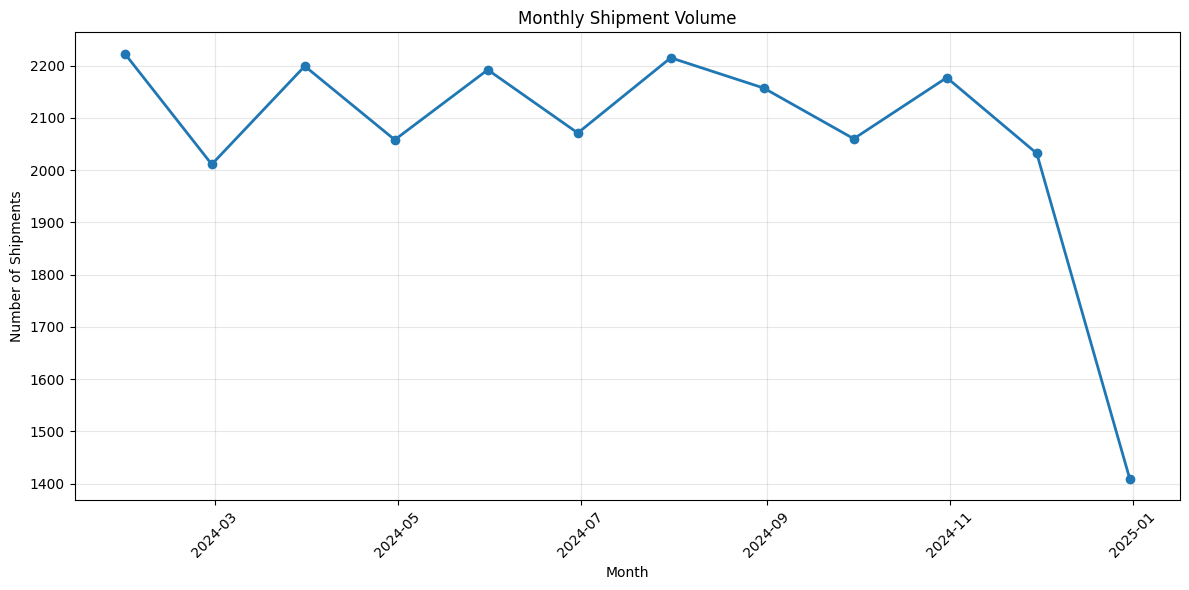

In [62]:
import matplotlib.pyplot as plt

# Create monthly shipment counts
monthly_shipments = (
    shipments
    .set_index("DispatchDate")
    .resample("ME")
    .size()
)

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_shipments.index,
    monthly_shipments.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Shipment Volume")
plt.xlabel("Month")
plt.ylabel("Number of Shipments")

plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

**Why this chart is appropriate:**  
A line chart is suitable for time-series data because it clearly shows changes
in shipment volume from month to month.

**Business insight:**  
The chart allows management to identify months with higher or lower shipment
activity. High-volume periods may require additional vehicles, warehouse
capacity and staff, while lower-volume periods may provide opportunities for
maintenance and resource planning.

### 2. Shipment Volume by Service Level

A bar chart was used to compare the number of shipments across different
service levels. This helps the business understand which logistics services
are most frequently used and where operational resources may be most needed.

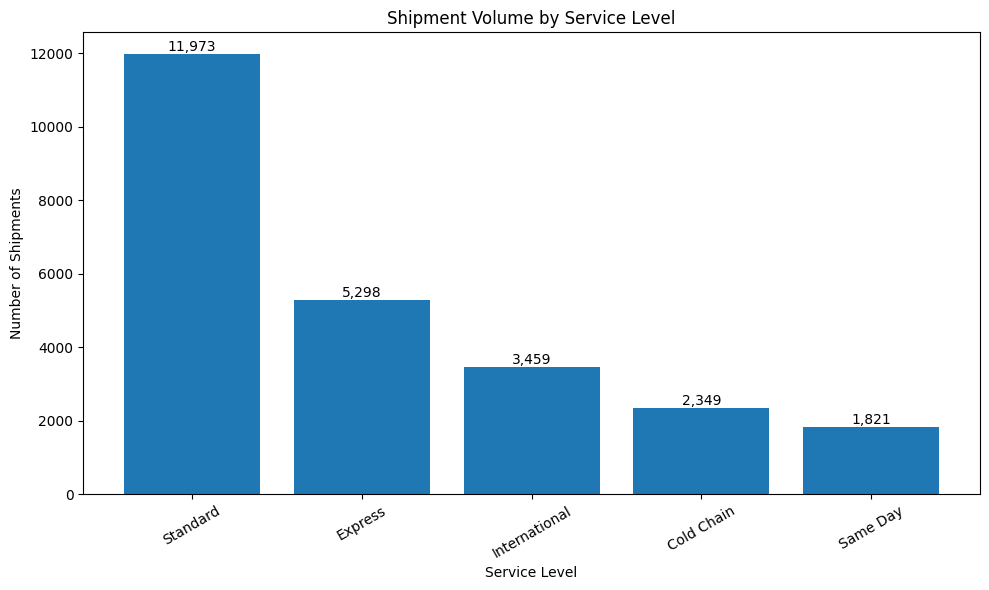

In [63]:
# Count shipments by service level
service_counts = (
    shipments["ServiceLevel"]
    .value_counts()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    service_counts.index,
    service_counts.values
)

plt.title("Shipment Volume by Service Level")
plt.xlabel("Service Level")
plt.ylabel("Number of Shipments")
plt.xticks(rotation=30)

# Add values above bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

**Why this chart is appropriate:**  
A bar chart is suitable for comparing shipment volumes across different
service-level categories.

**Business insight:**  
The chart shows which service levels account for the largest share of shipment
activity. Management can use this information for resource allocation,
capacity planning and service-level management. Categories with higher shipment
volumes may require greater operational capacity and closer performance
monitoring.

### 3. Relationship Between Distance and Total Cost

A scatter plot was used to examine the relationship between shipment distance
and total logistics cost. Each point represents an individual shipment.

This visualisation helps determine whether longer-distance shipments are
generally associated with higher transportation costs and also helps identify
unusual or potentially high-cost shipments.

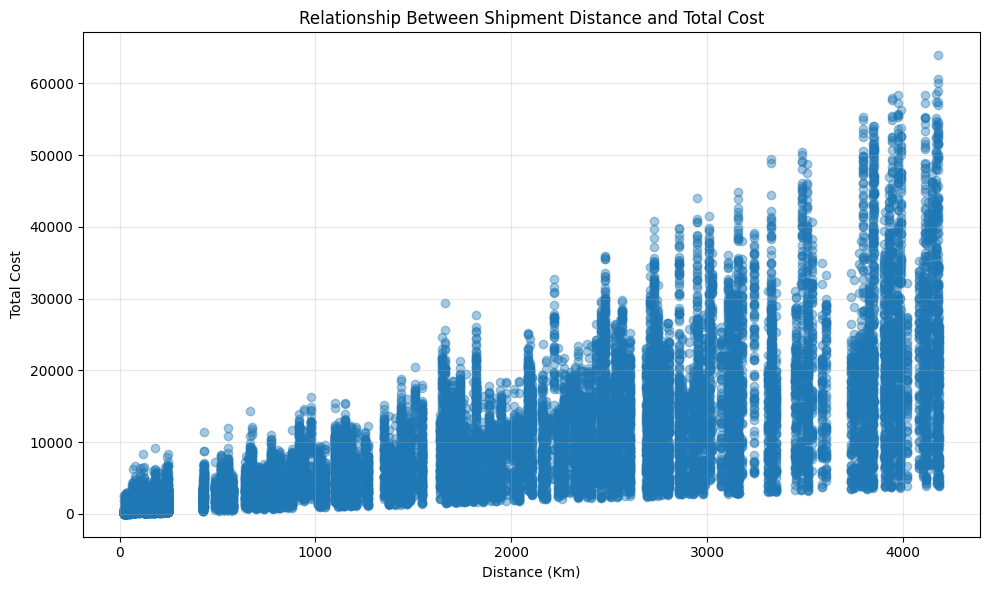

In [64]:
plt.figure(figsize=(10, 6))

plt.scatter(
    shipments["DistanceKm"],
    shipments["TotalCost"],
    alpha=0.4
)

plt.title("Relationship Between Shipment Distance and Total Cost")
plt.xlabel("Distance (Km)")
plt.ylabel("Total Cost")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [65]:
correlation = shipments["DistanceKm"].corr(
    shipments["TotalCost"]
)

print(
    "Correlation between DistanceKm and TotalCost:",
    round(correlation, 3)
)

Correlation between DistanceKm and TotalCost: 0.738


**Business insight:**  
The correlation between shipment distance and total cost was 0.738, indicating
a fairly strong positive relationship. In general, longer-distance shipments
tend to have higher total logistics costs.

However, the relationship is not perfect, which suggests that other factors
such as shipment weight, service level, fuel surcharge and shipment type may
also influence total cost. Management can use this information to investigate
high-cost routes and improve transportation cost planning.

### 4. Total Cost Distribution by Service Level

A box plot was used to compare the distribution of total shipment costs across
different service levels. This visualisation shows typical costs, variation and
potential unusually expensive shipments within each service category.

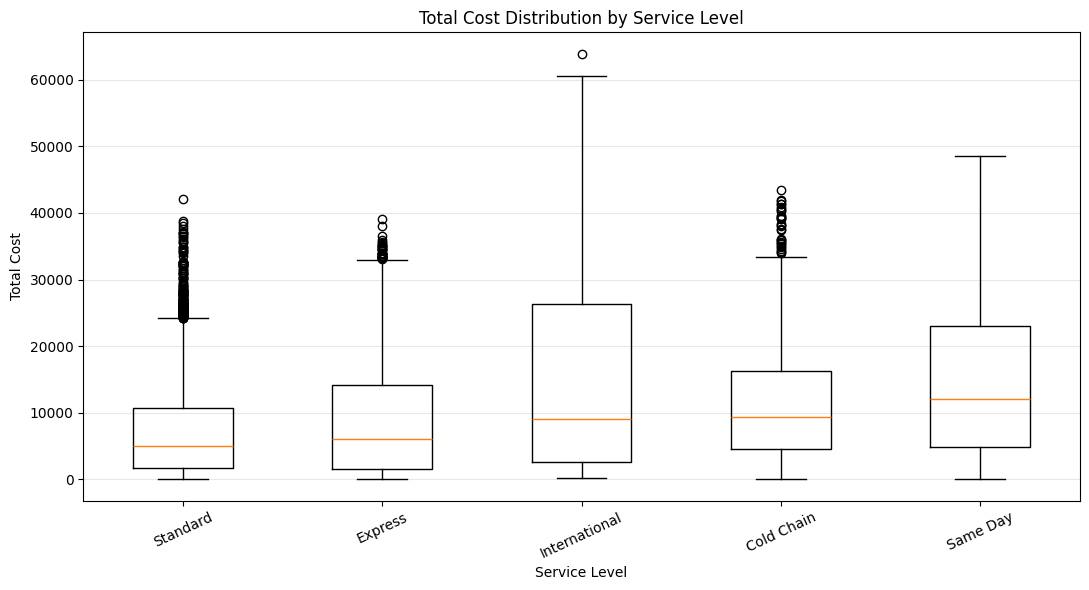

In [66]:
service_order = [
    "Standard",
    "Express",
    "International",
    "Cold Chain",
    "Same Day"
]

cost_data = [
    shipments.loc[
        shipments["ServiceLevel"] == service,
        "TotalCost"
    ].dropna()
    for service in service_order
]

plt.figure(figsize=(11, 6))

plt.boxplot(
    cost_data,
    tick_labels=service_order,
    showfliers=True
)

plt.title("Total Cost Distribution by Service Level")
plt.xlabel("Service Level")
plt.ylabel("Total Cost")
plt.xticks(rotation=25)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [67]:
service_cost_summary = (
    shipments
    .groupby("ServiceLevel")["TotalCost"]
    .agg(["count", "median", "mean"])
    .round(2)
    .sort_values("median", ascending=False)
)

service_cost_summary

,count,median,mean
ServiceLevel,,,
Same Day,1821,12090.32,14527.28
Cold Chain,2349,9323.70,11157.34
International,3459,9078.29,15590.52
Express,5298,6121.16,8844.59
Standard,11973,5087.69,7067.06


**Why this chart is appropriate:**  
A box plot is useful for comparing the distribution of shipment costs across
service levels. It shows the typical cost, variation in costs and unusually
high or low shipment costs within each service category.

**Business insight:**  
Same Day shipments had the highest median total cost at 12,090.32, followed by
Cold Chain at 9,323.70 and International at 9,078.29. Standard shipments had
the lowest median cost at 5,087.69.

International shipments had a mean cost of 15,590.52, which was considerably
higher than their median of 9,078.29. This suggests that some high-cost
International shipments are increasing the average.

These results indicate that service level is associated with substantial
differences in shipment costs. Management should investigate the cost drivers
of Same Day, Cold Chain and high-cost International shipments when reviewing
pricing and operational efficiency.

### 5. Correlation Heatmap of Shipment Variables

A correlation heatmap was created to examine relationships among important
numerical shipment variables. This helps identify variables that tend to move
together and highlights potential operational and financial relationships.

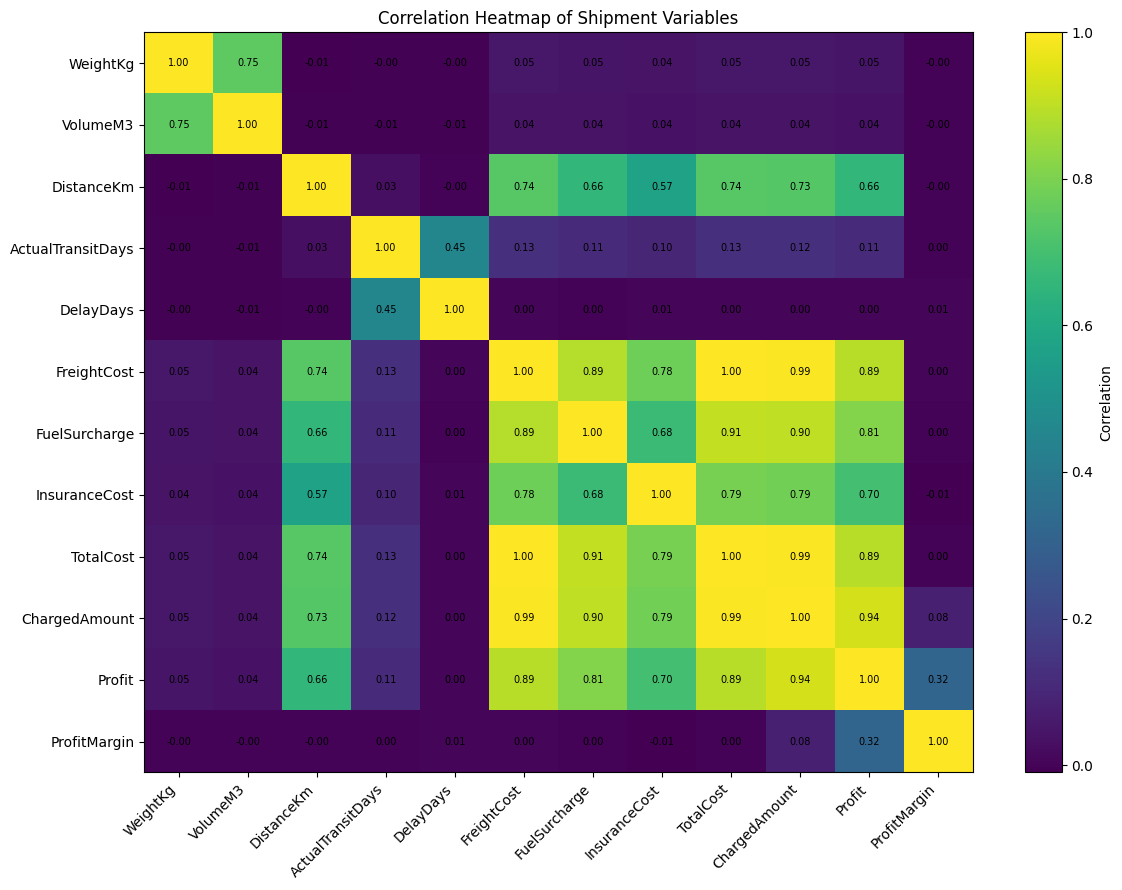

In [68]:
import numpy as np
import matplotlib.pyplot as plt

heatmap_columns = [
    "WeightKg",
    "VolumeM3",
    "DistanceKm",
    "ActualTransitDays",
    "DelayDays",
    "FreightCost",
    "FuelSurcharge",
    "InsuranceCost",
    "TotalCost",
    "ChargedAmount",
    "Profit",
    "ProfitMargin"
]

corr_matrix = shipments[heatmap_columns].corr()

plt.figure(figsize=(12, 9))

plt.imshow(
    corr_matrix,
    aspect="auto"
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(heatmap_columns)),
    heatmap_columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(heatmap_columns)),
    heatmap_columns
)

# Display correlation values
for i in range(len(heatmap_columns)):
    for j in range(len(heatmap_columns)):
        plt.text(
            j,
            i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=7
        )

plt.title("Correlation Heatmap of Shipment Variables")
plt.tight_layout()
plt.show()

In [69]:
# Show correlations with TotalCost
total_cost_corr = (
    corr_matrix["TotalCost"]
    .drop("TotalCost")
    .sort_values(ascending=False)
)

print("CORRELATION WITH TOTAL COST")
print("=" * 45)
print(total_cost_corr.round(3))

CORRELATION WITH TOTAL COST
FreightCost          0.998
ChargedAmount        0.994
FuelSurcharge        0.908
Profit               0.892
InsuranceCost        0.793
DistanceKm           0.738
ActualTransitDays    0.125
WeightKg             0.055
VolumeM3             0.043
DelayDays            0.002
ProfitMargin         0.001
Name: TotalCost, dtype: float64


**Why this chart is appropriate:**  
A correlation heatmap provides a compact way to examine the strength and
direction of relationships between multiple numerical variables at the same
time.

**Business insight:**  
TotalCost had a very strong positive correlation with FreightCost (0.998),
ChargedAmount (0.994) and FuelSurcharge (0.908). It was also strongly associated
with Profit (0.892) and InsuranceCost (0.793).

DistanceKm had a positive correlation of 0.738 with TotalCost, supporting the
earlier scatter plot finding that longer-distance shipments generally have
higher logistics costs.

In contrast, DelayDays (0.002), ProfitMargin (0.001), VolumeM3 (0.043) and
WeightKg (0.055) showed very weak linear relationships with TotalCost in this
dataset.

These results suggest that shipment cost is much more closely associated with
freight charges, fuel surcharges, insurance costs and distance than with delays,
weight or volume.

### 6. On-Time Delivery Performance by Service Level

On-time delivery performance was analysed across service levels to identify
whether particular services experience greater delivery reliability problems.
This is important because service reliability can influence customer
satisfaction and operational performance.

ON-TIME DELIVERY RATE BY SERVICE LEVEL
ServiceLevel
Express          87.64
Cold Chain       87.44
Standard         87.05
International    86.87
Same Day         83.53
Name: OnTimeFlag, dtype: float64


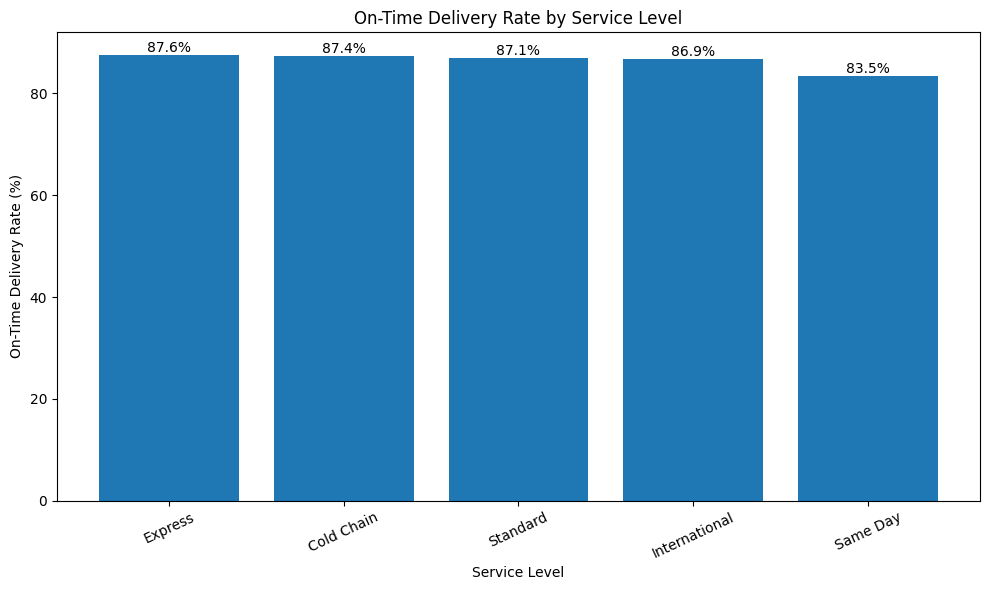

In [70]:
# Calculate on-time percentage by service level

on_time_by_service = (
    shipments
    .groupby("ServiceLevel")["OnTimeFlag"]
    .apply(lambda x: (x == "Y").mean() * 100)
    .sort_values(ascending=False)
)

print("ON-TIME DELIVERY RATE BY SERVICE LEVEL")
print("=" * 50)
print(on_time_by_service.round(2))

plt.figure(figsize=(10, 6))

bars = plt.bar(
    on_time_by_service.index,
    on_time_by_service.values
)

plt.title("On-Time Delivery Rate by Service Level")
plt.xlabel("Service Level")
plt.ylabel("On-Time Delivery Rate (%)")
plt.xticks(rotation=25)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

**Why this chart is appropriate:**  
A bar chart is appropriate for comparing on-time delivery rates across different
service-level categories. It makes differences in delivery reliability easy to
identify.

**Business insight:**  
Express recorded the highest on-time delivery rate at 87.64%, followed closely
by Cold Chain at 87.44% and Standard at 87.05%. International achieved 86.87%.

Same Day had the lowest on-time delivery rate at 83.53%, approximately four
percentage points below Express. This is particularly important because Same Day
also had the highest median shipment cost in the earlier cost analysis.

Management should investigate the operational factors affecting Same Day
deliveries, such as route planning, vehicle availability, warehouse processing
and dispatch scheduling. Improving Same Day reliability could help strengthen
service performance for this relatively high-cost service category.

### 7. Customer Satisfaction and Complaints

Customer satisfaction was compared between deliveries with and without
complaints. This analysis helps assess whether complaint occurrence is
associated with differences in the customer experience.

In [71]:
complaint_satisfaction = (
    delivery
    .groupby("ComplaintReceived")["CustomerSatisfaction"]
    .agg(["count", "mean", "median"])
    .round(2)
)

print("CUSTOMER SATISFACTION BY COMPLAINT STATUS")
print("=" * 55)
print(complaint_satisfaction)

CUSTOMER SATISFACTION BY COMPLAINT STATUS
                   count  mean  median
ComplaintReceived                     
N                   7686  4.14     4.0
Y                    314  3.40     4.0


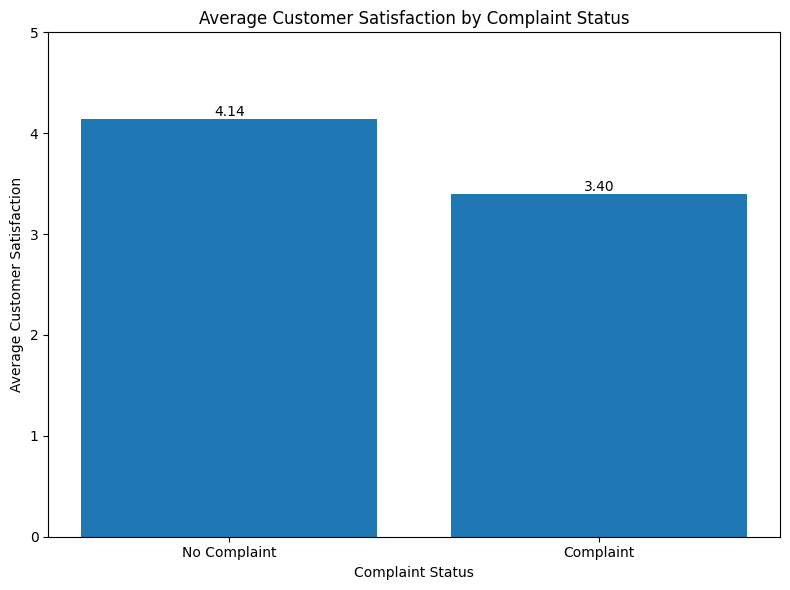

In [72]:
avg_satisfaction = (
    delivery
    .groupby("ComplaintReceived")["CustomerSatisfaction"]
    .mean()
)

labels = {
    "N": "No Complaint",
    "Y": "Complaint"
}

avg_satisfaction.index = [
    labels.get(x, x) for x in avg_satisfaction.index
]

plt.figure(figsize=(8, 6))

bars = plt.bar(
    avg_satisfaction.index,
    avg_satisfaction.values
)

plt.title("Average Customer Satisfaction by Complaint Status")
plt.xlabel("Complaint Status")
plt.ylabel("Average Customer Satisfaction")
plt.ylim(0, 5)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### 8. Delivery Delay by Shipment Type

Average delivery delay was analysed across shipment types to determine whether
particular types of freight experience greater delivery delays.

This analysis can help management identify shipment categories that may require
additional operational attention, specialised handling or improved scheduling.

In [73]:
delay_by_type = (
    shipments
    .groupby("ShipmentType")["DelayDays"]
    .mean()
    .sort_values(ascending=False)
)

print("AVERAGE DELAY BY SHIPMENT TYPE")
print("=" * 50)

print(delay_by_type.round(2))

AVERAGE DELAY BY SHIPMENT TYPE
ShipmentType
Cold Chain    0.74
Pallet        0.59
Bulk          0.58
Parcel        0.57
Container     0.52
Name: DelayDays, dtype: float64


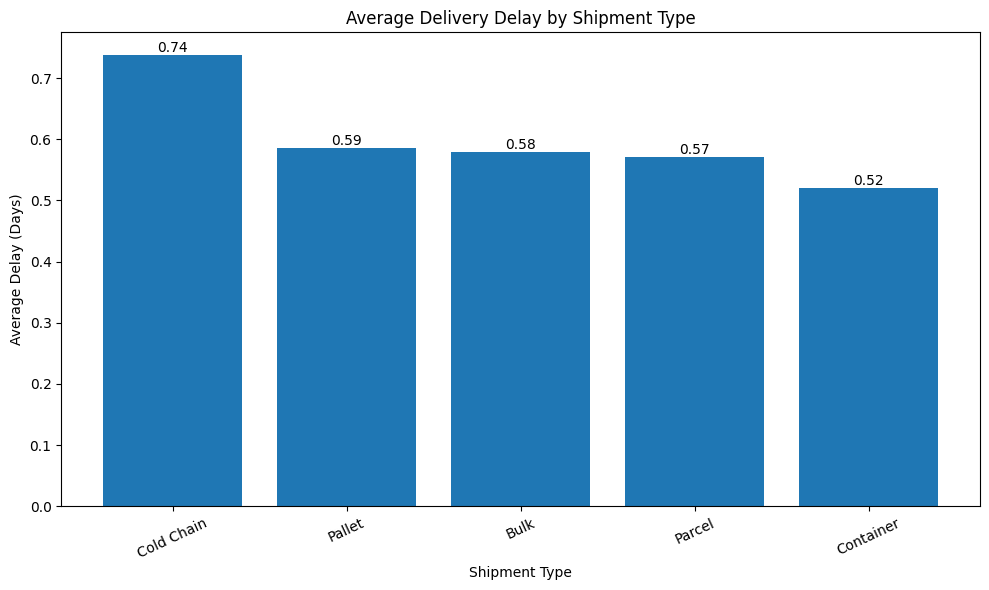

In [74]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    delay_by_type.index,
    delay_by_type.values
)

plt.title("Average Delivery Delay by Shipment Type")
plt.xlabel("Shipment Type")
plt.ylabel("Average Delay (Days)")
plt.xticks(rotation=25)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### 9. Profit Performance by Service Level

Profit performance was analysed across different service levels to understand
which service categories generate higher or lower profit per shipment.

This analysis helps management evaluate the financial performance of its
service offerings and identify areas for pricing or cost-management review.

In [75]:
profit_by_service = (
    shipments
    .groupby("ServiceLevel")["Profit"]
    .agg(["count", "mean", "median", "sum"])
    .round(2)
    .sort_values("mean", ascending=False)
)

print("PROFIT PERFORMANCE BY SERVICE LEVEL")
print("=" * 60)
print(profit_by_service)

PROFIT PERFORMANCE BY SERVICE LEVEL
               count     mean   median          sum
ServiceLevel                                       
International   3459  4280.98  2325.88  14807921.22
Same Day        1821  3984.38  3061.30   7255547.63
Cold Chain      2349  3127.36  2318.08   7346174.71
Express         5298  2440.20  1533.36  12928191.55
Standard       11973  1942.11  1264.65  23252913.10


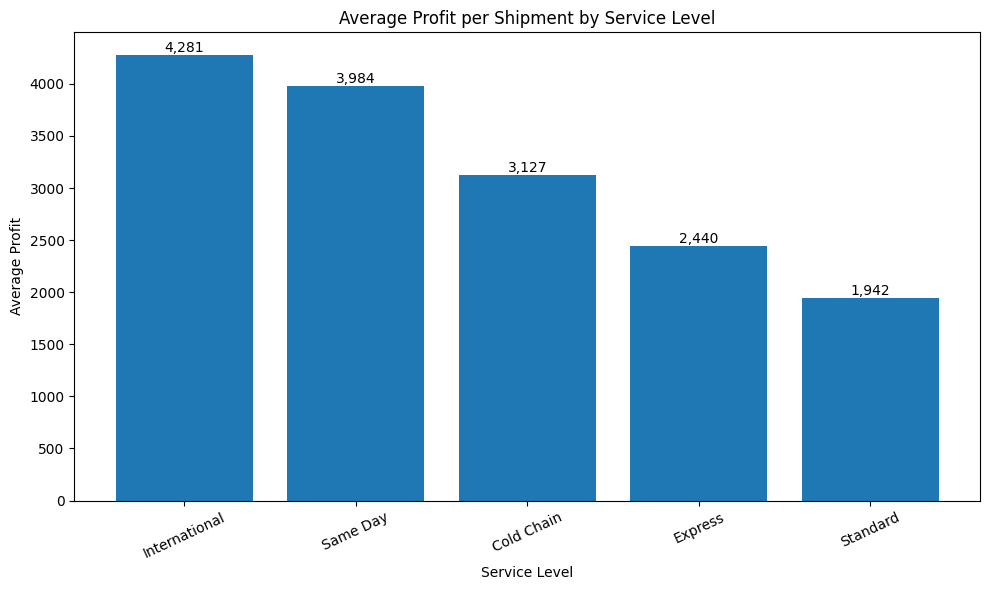

In [76]:
avg_profit = (
    shipments
    .groupby("ServiceLevel")["Profit"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_profit.index,
    avg_profit.values
)

plt.title("Average Profit per Shipment by Service Level")
plt.xlabel("Service Level")
plt.ylabel("Average Profit")
plt.xticks(rotation=25)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [77]:
total_shipments = len(shipments)

on_time_rate = (
    (shipments["OnTimeFlag"] == "Y").mean() * 100
)

average_delay = shipments["DelayDays"].mean()

damage_rate = (
    (shipments["DamageFlag"] == "Y").mean() * 100
)

print("OVERALL LOGISTICS KPI SUMMARY")
print("=" * 45)
print(f"Total Shipments: {total_shipments:,}")
print(f"Overall On-Time Rate: {on_time_rate:.2f}%")
print(f"Average Delay: {average_delay:.2f} days")
print(f"Damage Rate: {damage_rate:.2f}%")

OVERALL LOGISTICS KPI SUMMARY
Total Shipments: 24,900
Overall On-Time Rate: 86.93%
Average Delay: 0.59 days
Damage Rate: 3.03%


In [78]:
datasets = {
    "Shipments": shipments,
    "Customers": customers,
    "Warehouses": warehouses,
    "Carriers": carriers,
    "Routes": routes,
    "Vehicles": vehicles,
    "Delivery Performance": delivery
}

print("Datasets dictionary refreshed.")

Datasets dictionary refreshed.


In [79]:
# Reload original raw data for comparison

raw_shipments = pd.read_csv(
    "/content/mit635_data/Shipments.csv"
)

raw_customers = pd.read_csv(
    "/content/mit635_data/Customers.csv"
)

print("SHIPMENTS")
print("-" * 40)
print("Original rows:", len(raw_shipments))
print("Original duplicates:", raw_shipments.duplicated().sum())
print("Cleaned rows:", len(shipments))
print()

print("CUSTOMERS")
print("-" * 40)
print("Original rows:", len(raw_customers))
print("Original duplicates:", raw_customers.duplicated().sum())
print("Cleaned rows:", len(customers))

SHIPMENTS
----------------------------------------
Original rows: 25750
Original duplicates: 750
Cleaned rows: 24900

CUSTOMERS
----------------------------------------
Original rows: 4120
Original duplicates: 120
Cleaned rows: 4000


In [80]:
print("\nFINAL MISSING VALUE CHECK")
print("=" * 50)

for name, df in datasets.items():
    missing = df.isnull().sum()
    missing = missing[missing > 0]

    print(f"\n{name}")

    if len(missing) == 0:
        print("No missing values")
    else:
        print(missing)


FINAL MISSING VALUE CHECK

Shipments
DispatchDate     96
DeliveryDate    101
DistanceKm        5
dtype: int64

Customers
AccountStartDate    17
dtype: int64

Warehouses
No missing values

Carriers
No missing values

Routes
No missing values

Vehicles
No missing values

Delivery Performance
No missing values


In [81]:
print("\nFINAL DUPLICATE CHECK")
print("=" * 50)

for name, df in datasets.items():
    print(
        f"{name}: {df.duplicated().sum()} duplicate rows"
    )


FINAL DUPLICATE CHECK
Shipments: 0 duplicate rows
Customers: 0 duplicate rows
Warehouses: 0 duplicate rows
Carriers: 0 duplicate rows
Routes: 0 duplicate rows
Vehicles: 0 duplicate rows
Delivery Performance: 0 duplicate rows


In [82]:
raw_shipments = pd.read_csv(
    "/content/mit635_data/Shipments.csv"
)

raw_customers = pd.read_csv(
    "/content/mit635_data/Customers.csv"
)

print("SHIPMENTS")
print("-" * 40)
print("Original rows:", len(raw_shipments))
print("Original duplicates:", raw_shipments.duplicated().sum())
print("Cleaned rows:", len(shipments))

print("\nCUSTOMERS")
print("-" * 40)
print("Original rows:", len(raw_customers))
print("Original duplicates:", raw_customers.duplicated().sum())
print("Cleaned rows:", len(customers))

SHIPMENTS
----------------------------------------
Original rows: 25750
Original duplicates: 750
Cleaned rows: 24900

CUSTOMERS
----------------------------------------
Original rows: 4120
Original duplicates: 120
Cleaned rows: 4000


In [83]:
print("FINAL MISSING VALUE CHECK")
print("=" * 50)

for name, df in datasets.items():

    missing = df.isnull().sum()
    missing = missing[missing > 0]

    print(f"\n{name}")

    if len(missing) == 0:
        print("No missing values")
    else:
        print(missing)

FINAL MISSING VALUE CHECK

Shipments
DispatchDate     96
DeliveryDate    101
DistanceKm        5
dtype: int64

Customers
AccountStartDate    17
dtype: int64

Warehouses
No missing values

Carriers
No missing values

Routes
No missing values

Vehicles
No missing values

Delivery Performance
No missing values


In [85]:
# Find ShipmentIDs with missing DispatchDate
missing_dispatch_ids = shipments.loc[
    shipments["DispatchDate"].isna(),
    "ShipmentID"
]

print("ORIGINAL VALUES FOR MISSING DISPATCH DATES")
print("=" * 55)

display(
    raw_shipments[
        raw_shipments["ShipmentID"].isin(missing_dispatch_ids)
    ][["ShipmentID", "DispatchDate"]].head(20)
)

ORIGINAL VALUES FOR MISSING DISPATCH DATES


,ShipmentID,DispatchDate
54,SH0000055,invalid_date
96,SH0000097,2024-02-31
271,SH0000272,31/13/2024
306,SH0000307,2024-02-31
1656,SH0001657,invalid_date
1819,SH0001820,2024-02-31
1828,SH0001829,31/13/2024
1870,SH0001871,31/13/2024
2056,SH0002057,2024-02-31
2632,SH0002633,2024-02-31


In [86]:
# Find ShipmentIDs with missing DeliveryDate
missing_delivery_ids = shipments.loc[
    shipments["DeliveryDate"].isna(),
    "ShipmentID"
]

print("ORIGINAL VALUES FOR MISSING DELIVERY DATES")
print("=" * 55)

display(
    raw_shipments[
        raw_shipments["ShipmentID"].isin(missing_delivery_ids)
    ][["ShipmentID", "DeliveryDate"]].head(20)
)

ORIGINAL VALUES FOR MISSING DELIVERY DATES


,ShipmentID,DeliveryDate
338,SH0000339,31/13/2024
339,SH0000340,31/13/2024
350,SH0000351,invalid_date
682,SH0000683,2024-02-31
880,SH0000881,invalid_date
1577,SH0001578,2024-02-31
2079,SH0002080,2024-02-31
2127,SH0002128,invalid_date
2180,SH0002181,invalid_date
2775,SH0002776,2024-02-31


In [87]:
print("SHIPMENTS WITH MISSING DISTANCE")
print("=" * 55)

display(
    shipments.loc[
        shipments["DistanceKm"].isna(),
        ["ShipmentID", "RouteID", "DistanceKm"]
    ]
)

SHIPMENTS WITH MISSING DISTANCE


,ShipmentID,RouteID,DistanceKm
4463,SH0004464,Unknown,NaN
4529,SH0004530,Unknown,NaN
8903,SH0008904,Unknown,NaN
11297,SH0011298,Unknown,NaN
16363,SH0016364,Unknown,NaN


In [88]:
raw_customers = pd.read_csv(
    "/content/mit635_data/Customers.csv"
)

missing_account_ids = customers.loc[
    customers["AccountStartDate"].isna(),
    "CustomerID"
]

print("ORIGINAL VALUES FOR MISSING ACCOUNT START DATES")
print("=" * 55)

display(
    raw_customers[
        raw_customers["CustomerID"].isin(missing_account_ids)
    ][["CustomerID", "AccountStartDate"]].head(20)
)

ORIGINAL VALUES FOR MISSING ACCOUNT START DATES


,CustomerID,AccountStartDate
288,C00289,31/13/2024
298,C00299,invalid_date
583,C00584,31/13/2024
1385,C01386,invalid_date
1436,C01437,invalid_date
1458,C01459,31/13/2024
1486,C01487,31/13/2024
1536,C01537,2024-02-31
1542,C01543,2024-02-31
2226,C02227,31/13/2024


### Handling Invalid Customer Account Dates

Seventeen customer records contained invalid AccountStartDate values, including
"31/13/2024", "2024-02-31" and "invalid_date".

These values could not be reliably converted into valid dates because the
correct original dates were unknown. Rather than inventing dates, the invalid
values were retained as missing (NaT). This preserves the customer records while
avoiding the introduction of unsupported information into the dataset.

In [89]:
print("Missing DispatchDate:", shipments["DispatchDate"].isna().sum())
print("Missing DeliveryDate:", shipments["DeliveryDate"].isna().sum())

print("\nMISSING DISTANCE RECORDS")
display(
    shipments.loc[
        shipments["DistanceKm"].isna(),
        ["ShipmentID", "RouteID", "DistanceKm"]
    ]
)

Missing DispatchDate: 96
Missing DeliveryDate: 101

MISSING DISTANCE RECORDS


,ShipmentID,RouteID,DistanceKm
4463,SH0004464,Unknown,NaN
4529,SH0004530,Unknown,NaN
8903,SH0008904,Unknown,NaN
11297,SH0011298,Unknown,NaN
16363,SH0016364,Unknown,NaN


### Handling Missing Shipment Distance

Five shipment records had missing DistanceKm values and their RouteID values
were also unknown. Because no valid route information was available, the
distance could not be reliably recovered from the Routes dataset.

These five values were therefore retained as missing rather than estimated or
invented. The affected records represent only approximately 0.02% of the
cleaned shipment dataset and are excluded automatically from analyses that
require DistanceKm.

In [90]:
missing_dispatch_ids = shipments.loc[
    shipments["DispatchDate"].isna(),
    "ShipmentID"
]

missing_delivery_ids = shipments.loc[
    shipments["DeliveryDate"].isna(),
    "ShipmentID"
]

raw_bad_dispatch = raw_shipments.loc[
    raw_shipments["ShipmentID"].isin(missing_dispatch_ids),
    ["ShipmentID", "DispatchDate"]
]

raw_bad_delivery = raw_shipments.loc[
    raw_shipments["ShipmentID"].isin(missing_delivery_ids),
    ["ShipmentID", "DeliveryDate"]
]

print("INVALID / UNPARSED DISPATCH DATE VALUES")
print("=" * 50)
print(raw_bad_dispatch["DispatchDate"].value_counts(dropna=False))

print("\nINVALID / UNPARSED DELIVERY DATE VALUES")
print("=" * 50)
print(raw_bad_delivery["DeliveryDate"].value_counts(dropna=False))

INVALID / UNPARSED DISPATCH DATE VALUES
DispatchDate
2024-02-31      37
31/13/2024      35
invalid_date    25
Name: count, dtype: int64

INVALID / UNPARSED DELIVERY DATE VALUES
DeliveryDate
2024-02-31      41
invalid_date    33
31/13/2024      29
Name: count, dtype: int64


### Handling Invalid Shipment Dates

During date cleaning, several shipment records contained impossible or invalid
date values such as "2024-02-31", "31/13/2024" and "invalid_date".

After duplicate removal, 96 DispatchDate values and 101 DeliveryDate values
remained missing because the original values could not be converted into valid
calendar dates.

These values were retained as missing (NaT) rather than replaced with estimated
dates because the correct dates could not be determined reliably. This avoids
introducing artificial information into the dataset. Records with missing dates
are excluded from time-based analyses when a valid date is required.

In [91]:
print("FINAL CLEANING SUMMARY")
print("=" * 55)

print(f"Total cleaned shipments: {len(shipments):,}")
print(f"Duplicate shipments: {shipments.duplicated().sum()}")
print(f"Duplicate customers: {customers.duplicated().sum()}")

print("\nRemaining intentionally missing values:")
print(f"Shipment DispatchDate: {shipments['DispatchDate'].isna().sum()}")
print(f"Shipment DeliveryDate: {shipments['DeliveryDate'].isna().sum()}")
print(f"Shipment DistanceKm: {shipments['DistanceKm'].isna().sum()}")
print(f"Customer AccountStartDate: {customers['AccountStartDate'].isna().sum()}")

print("\nInvalid numeric values:")
print("Negative WeightKg:", (shipments["WeightKg"] < 0).sum())
print("Negative DistanceKm:", (shipments["DistanceKm"] < 0).sum())
print("Negative TotalCost:", (shipments["TotalCost"] < 0).sum())

print("\nKnown extreme placeholder values:")
print("WeightKg = 999999:", (shipments["WeightKg"] == 999999).sum())
print("DistanceKm = 99999:", (shipments["DistanceKm"] == 99999).sum())
print("TotalCost = 999999:", (shipments["TotalCost"] == 999999).sum())

FINAL CLEANING SUMMARY
Total cleaned shipments: 24,900
Duplicate shipments: 0
Duplicate customers: 0

Remaining intentionally missing values:
Shipment DispatchDate: 96
Shipment DeliveryDate: 101
Shipment DistanceKm: 5
Customer AccountStartDate: 17

Invalid numeric values:
Negative WeightKg: 0
Negative DistanceKm: 0
Negative TotalCost: 0

Known extreme placeholder values:
WeightKg = 999999: 0
DistanceKm = 99999: 0
TotalCost = 999999: 0


In [92]:
import os

clean_folder = "/content/mit635_cleaned"
os.makedirs(clean_folder, exist_ok=True)

shipments.to_csv(
    f"{clean_folder}/Shipments_Clean.csv",
    index=False
)

customers.to_csv(
    f"{clean_folder}/Customers_Clean.csv",
    index=False
)

warehouses.to_csv(
    f"{clean_folder}/Warehouses_Clean.csv",
    index=False
)

carriers.to_csv(
    f"{clean_folder}/Carriers_Clean.csv",
    index=False
)

routes.to_csv(
    f"{clean_folder}/Routes_Clean.csv",
    index=False
)

vehicles.to_csv(
    f"{clean_folder}/Vehicles_Clean.csv",
    index=False
)

delivery.to_csv(
    f"{clean_folder}/Delivery_Performance_Clean.csv",
    index=False
)

print("✅ FINAL CLEANED DATASETS EXPORTED")
print(os.listdir(clean_folder))

✅ FINAL CLEANED DATASETS EXPORTED
['Vehicles_Clean.csv', 'Carriers_Clean.csv', 'Warehouses_Clean.csv', 'Shipments_Clean.csv', 'Routes_Clean.csv', 'Delivery_Performance_Clean.csv', 'Customers_Clean.csv']


In [93]:
print("FINAL CLEANING SUMMARY")
print("=" * 55)

print(f"Total cleaned shipments: {len(shipments):,}")
print(f"Duplicate shipments: {shipments.duplicated().sum()}")
print(f"Duplicate customers: {customers.duplicated().sum()}")

print("\nRemaining intentionally missing values:")
print(f"Shipment DispatchDate: {shipments['DispatchDate'].isna().sum()}")
print(f"Shipment DeliveryDate: {shipments['DeliveryDate'].isna().sum()}")
print(f"Shipment DistanceKm: {shipments['DistanceKm'].isna().sum()}")
print(f"Customer AccountStartDate: {customers['AccountStartDate'].isna().sum()}")

print("\nInvalid numeric values:")
print("Negative WeightKg:", (shipments["WeightKg"] < 0).sum())
print("Negative DistanceKm:", (shipments["DistanceKm"] < 0).sum())
print("Negative TotalCost:", (shipments["TotalCost"] < 0).sum())

print("\nKnown extreme placeholder values:")
print("WeightKg = 999999:", (shipments["WeightKg"] == 999999).sum())
print("DistanceKm = 99999:", (shipments["DistanceKm"] == 99999).sum())
print("TotalCost = 999999:", (shipments["TotalCost"] == 999999).sum())

FINAL CLEANING SUMMARY
Total cleaned shipments: 24,900
Duplicate shipments: 0
Duplicate customers: 0

Remaining intentionally missing values:
Shipment DispatchDate: 96
Shipment DeliveryDate: 101
Shipment DistanceKm: 5
Customer AccountStartDate: 17

Invalid numeric values:
Negative WeightKg: 0
Negative DistanceKm: 0
Negative TotalCost: 0

Known extreme placeholder values:
WeightKg = 999999: 0
DistanceKm = 99999: 0
TotalCost = 999999: 0


In [94]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/MIT635_Final_Cleaned_Data",
    "zip",
    "/content/mit635_cleaned"
)

files.download("/content/MIT635_Final_Cleaned_Data.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>